# Sensor data preprocessing

Place complete environmental and occupancy CSV exports in `data` (subfolders are searched too). The newest matching export for each dataset is selected by file modification time; exports are not combined. Extra columns are ignored, while required columns and the supported JSON structure must remain present. The existing project-root CSVs are used only when no matching export is found in `data`. Keep the environmental location lookup in the project root or `data`. Run this pipeline cell from the repository root, then complete the active occupancy investigation audit and analysis cells below.


In [2]:
# Standard-library imports handle parsing, validation, filesystem operations, timing, and focused tests.
import json
import math
import os
import re
import shutil
import tempfile
import time
import unittest
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd

# The notebook is intentionally run from the repository root, so all project paths are deterministic.
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
# Repository-relative paths keep inputs, outputs, and reports in predictable locations.
DERIVED = ROOT / "derived"
ENV_OUTPUT_DIR = DERIVED / "environmental_measurements"
PREPROCESSING_OUTPUT_DIR = DERIVED / "preprocessing"
LEGACY_ENV_CSV = ROOT / "5EnvSensor_MayToDec2024_180kRows.csv"
LEGACY_OCC_CSV = ROOT / "5occupancySensor_MayToDec2024_9MRows.csv"
ENV_LOOKUP_NAME = "Sensor ID and Locations - ENV.csv"
ENV_LOOKUP = DATA_DIR / ENV_LOOKUP_NAME if (DATA_DIR / ENV_LOOKUP_NAME).is_file() else ROOT / ENV_LOOKUP_NAME
ENV_FULL = ENV_OUTPUT_DIR / "environmental_measurements_wide.csv"
ENV_REDUCED = ENV_OUTPUT_DIR / "environmental_measurements_wide_reduced.csv"
ENV_SCHEMA = ENV_OUTPUT_DIR / "environmental_measurements_wide_schema.csv"
ENV_VALIDATION = ENV_OUTPUT_DIR / "environmental_measurements_wide_validation.csv"
ENV_BENCHMARK = ENV_OUTPUT_DIR / "environmental_measurements_wide_benchmark.csv"
OCC_STREAMS = DERIVED / "occupancy_streams_by_floorspace"
MISSING_REPORT = PREPROCESSING_OUTPUT_DIR / "preprocessing_missing_data_report.csv"
CHANGE_REPORT = PREPROCESSING_OUTPUT_DIR / "preprocessing_changes.csv"
VALIDATION_REPORT = PREPROCESSING_OUTPUT_DIR / "preprocessing_validation.csv"
BENCHMARK_REPORT = PREPROCESSING_OUTPUT_DIR / "preprocessing_benchmark.csv"
STAGE_COMPARISON_REPORT = PREPROCESSING_OUTPUT_DIR / "preprocessing_raw_vs_processed_benchmark.csv"
# A fixed chunk size bounds intermediate CSV memory; it is a processing parameter, not a data filter.
CHUNK = 50_000
# These source identifiers are strict project-specific invariants checked before outputs are published.
SENSOR_ID = 6012000000000
DEVICE_ID = "56923747-b390-4f2a-8930-808429132266"
# Only these explicit textual tokens are normalized as missing; other malformed values are errors.
MISSING = {"", "nan", "null", "none"}
# These ordered required fields define the supported environmental CSV input contract.
ENV_COLS = ["id", "sensorid", "devicetype", "jsondata", "status", "processing_errors", "createdate", "processdate"]
# These ordered required fields define the supported occupancy CSV input contract.
OCC_COLS = ["id", "deviceid", "floorspaceid", "occupancystatus", "headcount", "collecteddate", "occupancystatuschangedate", "previousoccupancystatus"]
validation, changes, missing_report, benchmarks = [], [], [], []


def add_validation(check, result, observed, expected, notes=""):
    # Keep validation outcomes in memory until the complete run writes one consolidated report.
    validation.append({"check": check, "result": result, "observed": observed, "expected": expected, "notes": notes})


def add_change(dataset, source, output, operation, columns, reason, affected=0, before="", after=""):
    # Store repository-relative paths so the audit remains portable across machines.
    def relative(path):
        try:
            return Path(path).relative_to(ROOT).as_posix()
        except ValueError:
            return str(path)
    changes.append({"dataset": dataset, "source_file": relative(source), "output_file": relative(output), "operation": operation, "columns": columns, "reason": reason, "affected_rows": affected, "input_rows": before, "output_rows": after, "result": "PASS"})


def atomic_csv(frame, destination):
    # Stage beside the destination so os.replace remains an atomic same-volume operation.
    destination = Path(destination)
    # Create report folders lazily, including when the repository is freshly cloned.
    destination.parent.mkdir(parents=True, exist_ok=True)
    temp = None
    try:
        # Write to a sibling temporary file so a failed report write cannot truncate the existing report.
        with tempfile.NamedTemporaryFile(mode="w", encoding="utf-8", newline="", suffix=".csv", prefix=f".{destination.stem}.", dir=destination.parent, delete=False) as stream:
            temp = Path(stream.name)
            frame.to_csv(stream, index=False, lineterminator="\n", na_rep="NaN")
        os.replace(temp, destination)
        temp = None
    # Clean up the temporary artifact even when serialization or replacement raises.
    finally:
        if temp is not None and temp.exists():
            temp.unlink()


def discover_latest_csv(data_dir, required_columns, signature_columns, legacy_path, dataset):
    data_dir = Path(data_dir)
    required_columns = set(required_columns)
    signature_columns = set(signature_columns)
    matches, unsupported = [], []
    if data_dir.is_dir():
        # Search nested directories deterministically, but select by modification time rather than traversal order.
        for path in sorted(data_dir.rglob("*.csv")):
            if path.name == ENV_LOOKUP_NAME:
                continue
            headers = set(pd.read_csv(path, nrows=0, dtype=str, keep_default_na=False).columns)
            if required_columns.issubset(headers):
                matches.append(path)
            # Treat a file with dataset-specific signature fields but missing required fields as an invalid export, not as an unrelated CSV.
            elif headers & signature_columns:
                unsupported.append((path, sorted(required_columns - headers)))
    if unsupported:
        details = "; ".join(f"{path.name}: missing {missing}" for path, missing in unsupported)
        raise ValueError(f"{dataset}: raw CSV has an unsupported/incomplete schema: {details}")
    if matches:
        # Compare exact filesystem modification times and require the user to resolve a tie.
        newest_time = max(path.stat().st_mtime_ns for path in matches)
        newest = [path for path in matches if path.stat().st_mtime_ns == newest_time]
        if len(newest) != 1:
            raise ValueError(f"{dataset}: multiple matching exports share the newest modification time: {[path.name for path in newest]}")
        return newest[0], len(matches), "data"
    # The root-level path is a compatibility fallback only when the data folder has no matching export.
    legacy_path = Path(legacy_path)
    if legacy_path.is_file():
        return legacy_path, 0, "legacy"
    raise FileNotFoundError(f"{dataset}: no schema-matching CSV under {data_dir} and no legacy input at {legacy_path}")


# Select a complete replacement export per sensor family; never concatenate snapshots.
ENV_CSV, env_export_count, env_selection_source = discover_latest_csv(DATA_DIR, ENV_COLS, {"jsondata", "sensorid"}, LEGACY_ENV_CSV, "environmental")
OCC_CSV, occ_export_count, occ_selection_source = discover_latest_csv(DATA_DIR, OCC_COLS, {"floorspaceid", "headcount", "collecteddate"}, LEGACY_OCC_CSV, "occupancy")
for dataset, path, export_count, source in (
    ("environmental", ENV_CSV, env_export_count, env_selection_source),
    ("occupancy", OCC_CSV, occ_export_count, occ_selection_source),
):
    selected = path.relative_to(ROOT).as_posix()
    if source == "data":
        add_validation(f"{dataset}_input_selection", "PASS", selected, "newest complete export under data", f"Selected from {export_count} schema-matching export(s) by modification time; other exports were not combined.")
    else:
        add_validation(f"{dataset}_input_selection", "INFO", selected, "newest complete export under data", "No matching export was found under data; used the legacy project-root input.")


def numeric_or_nan(series, label):
    # Keep missing tokens distinct from zero and reject invalid nonmissing values.
    text = series.astype("string").str.strip()
    # Separate explicit missing markers before numeric conversion so they never become zero.
    missing = text.isna() | text.str.casefold().isin(MISSING)
    numeric = pd.to_numeric(text.mask(missing), errors="coerce")
    # A conversion failure is only an error for a nonmissing input token.
    bad = (~missing) & numeric.isna()
    if bad.any():
        raise ValueError(f"{label}: non-numeric value {text.loc[bad].iloc[0]!r}")
    # Reject infinities as well as nonnumeric text because neither is a valid measurement.
    if (numeric.dropna().map(math.isfinite) == False).any():
        raise ValueError(f"{label}: non-finite numeric value")
    return numeric, missing


def feature_slug(value):
    value = str(value).casefold().replace("2.5", "2_5")
    # Keep generated feature names deterministic and safe as CSV column labels.
    return re.sub(r"[^a-z0-9]+", "_", value).strip("_") or "unnamed"


def validate_env_lookup():
    lookup = pd.read_csv(ENV_LOOKUP, dtype=str, keep_default_na=False)
    if lookup.empty or not {"Sensor", "ID"}.issubset(lookup.columns):
        raise ValueError(f"{ENV_LOOKUP.name}: required Sensor/ID columns or rows missing")
    # Validate lookup IDs numerically so formatting such as scientific notation does not evade the sensor check.
    ids = pd.to_numeric(lookup["ID"], errors="coerce")
    if not lookup["Sensor"].eq("Env").all() or ids.isna().any() or not ids.eq(SENSOR_ID).all():
        raise ValueError(f"{ENV_LOOKUP.name}: unexpected sensor or ID")
    add_validation("ENV_location_lookup", "PASS", len(lookup), "Sensor=Env; ID=6012000000000")


def parse_json_payload(raw, record_id):
    try:
        payload = json.loads(raw)
    # Attach the source record ID to parse errors so a bad payload can be traced back to raw data.
    except (json.JSONDecodeError, TypeError) as exc:
        raise ValueError(f"Environmental record {record_id}: invalid JSON") from exc
    if not isinstance(payload, list):
        raise ValueError(f"Environmental record {record_id}: payload is not a list")
    # Collect values and enforce one consistent measurement instant per source record.
    measurements, metadata, times = {}, {}, set()
    for entry in payload:
        # Reject structurally incomplete JSON rather than silently dropping a variable.
        if not isinstance(entry, dict) or not isinstance(entry.get("variable"), dict):
            raise ValueError(f"Environmental record {record_id}: malformed measurement")
        variable = entry["variable"]
        var_id = str(variable.get("id", ""))
        if not var_id.isdigit() or var_id in measurements:
            raise ValueError(f"Environmental record {record_id}: invalid/duplicate variable ID")
        # Retain units and source metadata with each generated variable for later interpretation.
        descriptor = {"variable_id": var_id, "variable": str(variable.get("name", "")), "unit": str(variable.get("unit", "")), "source": str(variable.get("source", "")), "structure": str(variable.get("structure", "")), "output_column": f"var_{var_id}_{feature_slug(variable.get('name', ''))}"}
        metadata[var_id] = descriptor
        points = entry.get("values")
        # The wide transform supports at most one observation per variable in a source event.
        if not isinstance(points, list) or len(points) > 1:
            raise ValueError(f"Environmental record {record_id}: variable {var_id} must have at most one value point")
        # An empty values array indicates a missing measurement, not a zero-valued observation.
        if not points:
            measurements[var_id] = float("nan")
            continue
        if not isinstance(points[0], dict):
            raise ValueError(f"Environmental record {record_id}: variable {var_id} has a malformed value point")
        point = points[0]
        stamp = point.get("time")
        # Booleans are integers in Python, but are not valid Unix timestamps for this dataset.
        if stamp is None or isinstance(stamp, bool):
            raise ValueError(f"Environmental record {record_id}: missing measurement time")
        try:
            times.add(int(stamp))
        except (TypeError, ValueError, OverflowError) as exc:
            raise ValueError(f"Environmental record {record_id}: invalid measurement time") from exc
        value = point.get("value")
        # Preserve JSON null as NaN; do not let the later numeric pipeline interpret it as zero.
        if value is None:
            measurements[var_id] = float("nan")
        else:
            try:
                value = float(value)
            except (TypeError, ValueError, OverflowError) as exc:
                raise ValueError(f"Environmental record {record_id}: non-numeric variable {var_id}") from exc
            if not math.isfinite(value):
                raise ValueError(f"Environmental record {record_id}: non-finite variable {var_id}")
            measurements[var_id] = value
    # All feature measurements in one source event must share one timestamp for a coherent wide row.
    if len(times) != 1:
        raise ValueError(f"Environmental record {record_id}: expected one shared measurement timestamp")
    timestamp = datetime.fromtimestamp(next(iter(times)), tz=timezone.utc).isoformat().replace("+00:00", "Z")
    return timestamp, measurements, metadata


def build_environmental_outputs():
    # Inspect only headers first; this fails early before an expensive full-data pass.
    headers = list(pd.read_csv(ENV_CSV, nrows=0, dtype=str, keep_default_na=False).columns)
    if not set(ENV_COLS).issubset(headers):
        raise ValueError(f"{ENV_CSV.name}: required environmental columns missing: {sorted(set(ENV_COLS) - set(headers))}")
    # First pass establishes the complete feature schema before any wide rows are written.
    descriptors, seen_ids = {}, set()
    row_count = equal_dates = timestamp_pairs = 0
    # Count source missing tokens by field while streaming rather than retaining the full source table.
    raw_missing = dict.fromkeys(ENV_COLS, 0)
    # The first pass validates every source event and discovers all feature metadata before output columns are fixed.
    for chunk in pd.read_csv(ENV_CSV, usecols=ENV_COLS, dtype=str, keep_default_na=False, chunksize=CHUNK):
        chunk = chunk.reindex(columns=ENV_COLS)
        row_count += len(chunk)
        for col in ENV_COLS:
            raw_missing[col] += int(chunk[col].str.strip().str.casefold().isin(MISSING).sum())
        ids = chunk["id"].astype(str)
        # Check uniqueness both within the current chunk and against IDs seen in prior chunks.
        if ids.eq("").any() or ids.duplicated().any() or not seen_ids.isdisjoint(ids):
            raise ValueError("Environmental record IDs are blank or duplicated")
        seen_ids.update(ids)
        sensor = pd.to_numeric(chunk["sensorid"], errors="coerce")
        if sensor.isna().any() or not sensor.eq(SENSOR_ID).all():
            raise ValueError("Unexpected environmental sensor ID")
        # These categorical constants are part of the validated source contract, not inferred assumptions.
        for column, expected in (("devicetype", "env"), ("status", "Processed"), ("processing_errors", "NULL")):
            if not chunk[column].eq(expected).all():
                raise ValueError(f"Unexpected environmental {column}")
        created = pd.to_datetime(chunk["createdate"], errors="coerce", utc=True)
        processed = pd.to_datetime(chunk["processdate"], errors="coerce", utc=True)
        if created.isna().any() or processed.isna().any():
            raise ValueError("Invalid createdate/processdate")
        # Count parsed record-time equality across the full input; dropping processdate requires every row to match.
        equal_dates += int(created.eq(processed).sum())
        timestamp_pairs += len(chunk)
        for record_id, raw in chunk[["id", "jsondata"]].itertuples(index=False, name=None):
            _, _, row_metadata = parse_json_payload(raw, record_id)
            for key, descriptor in row_metadata.items():
                # Stable variable metadata ensures a single output column and unit meaning across records.
                if key in descriptors and descriptors[key] != descriptor:
                    raise ValueError(f"Environmental variable {key}: metadata changes between records")
                descriptors[key] = descriptor
    if row_count == 0 or not descriptors:
        raise ValueError("Environmental input is empty")
    # Numeric sorting keeps feature order stable even when variable IDs have different digit lengths.
    variables = sorted(descriptors, key=int)
    features = [descriptors[key]["output_column"] for key in variables]
    # Distinct source variables must not collapse to the same normalized output name.
    if len(features) != len(set(features)):
        raise ValueError("Measurement variable names collide after normalization")
    schema = pd.DataFrame([descriptors[key] for key in variables])
    atomic_csv(schema, ENV_SCHEMA)

    # Keep source identity and both relevant time concepts explicit in the full output schema.
    columns = ["source_record_id", "sensor_id", "devicetype", "createdate", "processdate", "timestamp_utc", *features]
    missing_by_feature = dict.fromkeys(features, 0)
    temp = None
    written = 0
    try:
        with tempfile.NamedTemporaryFile(mode="w", encoding="utf-8", newline="", suffix=".csv", prefix=".environmental-wide.", dir=ENV_OUTPUT_DIR, delete=False) as out:
            temp = Path(out.name)
            first = True
            for chunk in pd.read_csv(ENV_CSV, usecols=ENV_COLS, dtype=str, keep_default_na=False, chunksize=CHUNK):
                chunk = chunk.reindex(columns=ENV_COLS)
                records = []
                # Expand each source event against the schema discovered in the first pass.
                for record in chunk.itertuples(index=False, name=None):
                    record_id, sensor, device, raw_json, _, _, created, processed = record
                    stamp, values, _ = parse_json_payload(raw_json, record_id)
                    item = {"source_record_id": record_id, "sensor_id": str(SENSOR_ID), "devicetype": device, "createdate": created, "processdate": processed, "timestamp_utc": stamp}
                    # Use NaN for a variable absent from a record so every row shares one rectangular schema.
                    for key in variables:
                        item[descriptors[key]["output_column"]] = values.get(key, float("nan"))
                    records.append(item)
                # Construct each bounded output batch only after parsing the source chunk.
                expanded = pd.DataFrame(records, columns=columns)
                for feature in features:
                    normalized, is_missing = numeric_or_nan(expanded[feature], feature)
                    missing_by_feature[feature] += int(is_missing.sum())
                    expanded[feature] = normalized
                expanded.to_csv(out, index=False, header=first, lineterminator="\n", na_rep="NaN")
                first = False
                written += len(expanded)
        if written != row_count:
            raise ValueError(f"Wide output has {written} rows; expected {row_count}")
        # Publish only after row-count validation; replacement avoids exposing a partially written CSV.
        os.replace(temp, ENV_FULL)
        temp = None
    finally:
        if temp is not None and temp.exists():
            temp.unlink()

    # Remove fields only after their invariance has been checked across the full input.
    excluded = {"sensor_id", "devicetype"}
    # Drop processdate only when equality holds for every parsed row, never based on a sample.
    if equal_dates == timestamp_pairs:
        excluded.add("processdate")
    selected = [col for col in columns if col not in excluded]
    temp = None
    reduced_rows = 0
    try:
        with tempfile.NamedTemporaryFile(mode="w", encoding="utf-8", newline="", suffix=".csv", prefix=".environmental-reduced.", dir=ENV_OUTPUT_DIR, delete=False) as out:
            temp = Path(out.name)
            first = True
            # Build the reduced file from the validated full output so it is a deterministic column selection.
            for chunk in pd.read_csv(ENV_FULL, usecols=selected, dtype=str, keep_default_na=False, chunksize=CHUNK):
                for feature in features:
                    chunk[feature], _ = numeric_or_nan(chunk[feature], feature)
                chunk.to_csv(out, index=False, header=first, lineterminator="\n", na_rep="NaN")
                first = False
                reduced_rows += len(chunk)
        if reduced_rows != row_count:
            raise ValueError("Reduced environmental output changed the row count")
        os.replace(temp, ENV_REDUCED)
        temp = None
    finally:
        if temp is not None and temp.exists():
            temp.unlink()

    # Reports describe checks performed on the complete source, not only the current chunk.
    add_validation("environmental_rows_and_json", "PASS", f"{row_count:,} rows; {len(features)} variables", "one valid wide row per raw record")
    add_validation("environmental_ids", "PASS", len(seen_ids), row_count, "unique and nonblank")
    add_validation("environmental_constants", "PASS", "sensorid/devicetype/status/processing_errors", "all expected constants")
    add_validation("environmental_record_timestamps", "PASS" if equal_dates == timestamp_pairs else "INFO", f"{equal_dates:,}/{timestamp_pairs:,} equal", "parseable timestamps; equality required to drop processdate")
    add_change("environmental", ENV_CSV, ENV_FULL, "expand_json_to_wide", "jsondata -> measurement columns", "One wide row per source record; raw JSON left untouched.", row_count, row_count, written)
    add_change("environmental", ENV_CSV, ENV_FULL, "normalize_missing_measurements_to_NaN", ",".join(features), "Empty values arrays, JSON nulls, and absent variables become NaN in derived measurements.", sum(missing_by_feature.values()), row_count, written)
    add_change("environmental", ENV_FULL, ENV_REDUCED, "exclude_verified_columns", ",".join(sorted(excluded)), "Remove validated constants and equal processdate; retain measurement timestamp.", row_count, row_count, reduced_rows)
    for feature, count in missing_by_feature.items():
        missing_report.append({"dataset": "environmental", "column": feature, "missing_type": "missing_measurement", "count": count, "handling": "NaN in derived wide outputs; raw JSON and source rows unchanged."})
    return {"rows": row_count, "features": features, "columns": columns, "selected": selected, "excluded": sorted(excluded), "missing": missing_by_feature, "timestamp_equal": equal_dates}


def validate_wide_file(path, raw_rows, reduced):
    schema = pd.read_csv(ENV_SCHEMA, dtype=str, keep_default_na=False)
    features = schema["output_column"].tolist()
    headers = list(pd.read_csv(path, nrows=0, dtype=str, keep_default_na=False).columns)
    # Require identifiers, both relevant timestamps, and every feature listed by the generated schema.
    expected = set(["source_record_id", "createdate", "timestamp_utc", *features])
    if not expected.issubset(headers):
        raise ValueError(f"{path.name}: required output columns missing")
    if not reduced and not {"sensor_id", "devicetype", "processdate"}.issubset(headers):
        raise ValueError(f"{path.name}: full output columns missing")
    # Track IDs across chunks to catch duplicates that are separated in the file.
    ids, rows = set(), 0
    for chunk in pd.read_csv(path, dtype=str, keep_default_na=False, chunksize=CHUNK):
        rows += len(chunk)
        chunk_ids = chunk["source_record_id"].astype(str)
        if chunk_ids.eq("").any() or chunk_ids.duplicated().any() or not ids.isdisjoint(chunk_ids):
            raise ValueError(f"{path.name}: duplicate/blank source record ID")
        ids.update(chunk_ids)
        if pd.to_datetime(chunk["timestamp_utc"], errors="coerce", utc=True).isna().any():
            raise ValueError(f"{path.name}: invalid measurement timestamp")
        for feature in features:
            numeric_or_nan(chunk[feature], feature)
    if rows != raw_rows or len(ids) != raw_rows:
        raise ValueError(f"{path.name}: row/ID count differs from raw input")
    add_validation(f"{path.stem}_schema_rows_ids", "PASS", f"{rows:,} rows; {len(headers)} columns", f"{raw_rows:,} matching unique IDs", "Measurement fields are numeric or NaN.")


def audit_change_date(path):
    data = pd.read_csv(path, usecols=["id", "headcount", "collecteddate", "occupancystatuschangedate"], dtype=str, keep_default_na=False)
    ids = pd.to_numeric(data["id"], errors="coerce")
    count, _ = numeric_or_nan(data["headcount"], "headcount")
    collected = pd.to_datetime(data["collecteddate"], errors="coerce", utc=True)
    changed = pd.to_datetime(data["occupancystatuschangedate"], errors="coerce", utc=True)
    if ids.isna().any() or collected.isna().any() or changed.isna().any():
        raise ValueError(f"{path.name}: invalid ID or timestamp in change-date audit")
    # Sort events into time order before using shifted rows to compare adjacent occupancy states.
    data = data.assign(_id=ids, _count=count, _collected=collected, _changed=changed).sort_values(["_collected", "_id"], kind="stable").reset_index(drop=True)
    # Shifted values represent the preceding event after sorting, enabling zero-to-positive and positive-run checks.
    previous_count, previous_changed = data["_count"].shift(), data["_changed"].shift()
    zero, positive = data["_count"].eq(0), data["_count"].gt(0)
    starts, runs = positive & previous_count.eq(0), positive & previous_count.gt(0)
    zero_match = zero & data["_changed"].eq(data["_collected"])
    start_match = starts & data["_changed"].eq(data["_collected"])
    run_match = runs & data["_changed"].eq(previous_changed)
    start_bad = starts & ~data["_changed"].eq(data["_collected"])
    run_bad = runs & ~data["_changed"].eq(previous_changed)
    # Return counts and first exception IDs so patterns can be reviewed without retaining the entire stream.
    return {"floorspaceid": path.stem, "rows": len(data), "zero_readings": int(zero.sum()), "zero_time_matches": int(zero_match.sum()), "positive_starts_after_zero": int(starts.sum()), "positive_start_time_matches": int(start_match.sum()), "positive_start_first_exception_id": str(data.loc[start_bad, "id"].iloc[0]) if start_bad.any() else "", "successive_positive_pairs": int(runs.sum()), "unchanged_time_in_positive_run": int(run_match.sum()), "positive_run_time_changes": int(run_bad.sum()), "positive_run_first_exception_id": str(data.loc[run_bad, "id"].iloc[0]) if run_bad.any() else ""}


def build_occupancy_streams():
    headers = list(pd.read_csv(OCC_CSV, nrows=0, dtype=str, keep_default_na=False).columns)
    if not set(OCC_COLS).issubset(headers):
        raise ValueError(f"{OCC_CSV.name}: required occupancy columns missing: {sorted(set(OCC_COLS) - set(headers))}")
    # Stage large partitioned outputs outside the final directory; incomplete runs should not appear as completed streams.
    temp_root = Path(tempfile.mkdtemp(prefix=".occupancy-preprocessing."))
    staging, final = temp_root / "staging", temp_root / "final"
    staging.mkdir()
    final.mkdir()
    rows_by_space, source_rows = {}, 0
    unknown = blank_previous = timestamp_equal = 0
    # Accumulate missing-token counts by original field while reading occupancy chunks.
    raw_missing = dict.fromkeys(OCC_COLS, 0)
    count_min = count_max = None
    try:
        for chunk in pd.read_csv(OCC_CSV, usecols=OCC_COLS, dtype=str, keep_default_na=False, chunksize=CHUNK):
            chunk = chunk.reindex(columns=OCC_COLS)
            source_rows += len(chunk)
            for col in OCC_COLS:
                raw_missing[col] += int(chunk[col].str.strip().str.casefold().isin(MISSING).sum())
            if not chunk["deviceid"].eq(DEVICE_ID).all():
                raise ValueError("Unexpected occupancy deviceid")
            if chunk["floorspaceid"].str.strip().str.casefold().isin(MISSING).any():
                raise ValueError("Occupancy floorspaceid is missing")
            headcount, _ = numeric_or_nan(chunk["headcount"], "occupancy headcount")
            # Apply range and integrality checks only to observed counts; NaN is allowed and retained.
            valid = headcount.dropna()
            if (valid < 0).any() or ((valid % 1) != 0).any():
                raise ValueError("Occupancy headcount must be a nonnegative integer or missing")
            if not valid.empty:
                count_min = valid.min() if count_min is None else min(count_min, valid.min())
                count_max = valid.max() if count_max is None else max(count_max, valid.max())
            collected = pd.to_datetime(chunk["collecteddate"], errors="coerce", utc=True)
            changed = pd.to_datetime(chunk["occupancystatuschangedate"], errors="coerce", utc=True)
            if collected.isna().any() or changed.isna().any():
                raise ValueError("Occupancy timestamps contain invalid values")
            timestamp_equal += int(collected.eq(changed).sum())
            # Normalize case/whitespace only for counting unknown history; raw categories remain untouched.
            previous = chunk["previousoccupancystatus"].str.strip().str.casefold()
            unknown += int(previous.eq("unknown").sum())
            blank_previous += int(previous.isin(MISSING).sum())
            chunk["headcount"] = headcount
            # Partition each chunk by location to avoid loading the multi-million-row source at once.
            for space, group in chunk[["id", "floorspaceid", "headcount", "collecteddate", "occupancystatuschangedate"]].groupby("floorspaceid", sort=False):
                # Reject path separators and Windows-invalid filename characters before using a floorspace ID as a filename.
                if any(char in space for char in '<>:"/\\|?*') or space.rstrip(" .") != space:
                    raise ValueError(f"Invalid floorspace ID for output filename {space!r}")
                path = staging / f"{space}.csv"
                group.to_csv(path, mode="a" if path.exists() else "w", header=not path.exists(), index=False, lineterminator="\n", na_rep="NaN")
                rows_by_space[space] = rows_by_space.get(space, 0) + len(group)
        if source_rows == 0:
            raise ValueError("Occupancy source is empty")
        audits = []
        # Audit the change timestamp while available, then omit it from the analytical streams.
        for space in sorted(rows_by_space):
            source = staging / f"{space}.csv"
            # Audit the temporary stream that still contains the change timestamp, before creating the reduced analytical stream.
            audit = audit_change_date(source)
            if audit["rows"] != rows_by_space[space]:
                raise ValueError(f"{source.name}: change-date audit row mismatch")
            audits.append(audit)
            target = final / source.name
            first, count = True, 0
            for chunk in pd.read_csv(source, dtype=str, keep_default_na=False, chunksize=CHUNK):
                # Drop only after the audit; the output retains the observation timestamp and headcount.
                chunk.drop(columns=["occupancystatuschangedate"]).to_csv(target, mode="w" if first else "a", header=first, index=False, lineterminator="\n", na_rep="NaN")
                count += len(chunk)
                first = False
            # Check per-partition conservation before publishing any staged stream.
            if count != rows_by_space[space]:
                raise ValueError(f"{target.name}: output row count mismatch")
        pd.DataFrame([{"floorspaceid": key, "row_count": value} for key, value in rows_by_space.items()]).to_csv(final / "stream_row_counts.csv", index=False)
        audit_frame = pd.DataFrame(audits)
        audit_frame.to_csv(final / "occupancystatuschangedate_audit.csv", index=False)
        # Publish validated staged files individually for safer replacement on Windows/OneDrive.
        if OCC_STREAMS.exists():
            staged_names = {path.name for path in final.iterdir()}
            if any(path.is_dir() for path in OCC_STREAMS.iterdir()):
                raise ValueError(f"Unexpected subdirectory in derived occupancy output: {OCC_STREAMS}")
            for staged_file in final.iterdir():
                os.replace(staged_file, OCC_STREAMS / staged_file.name)
            # Remove obsolete prior partitions only after every replacement partition has been staged and validated.
            for stale_file in OCC_STREAMS.iterdir():
                if stale_file.name not in staged_names:
                    stale_file.unlink()
        else:
            final.rename(OCC_STREAMS)
        add_validation("occupancy_rows_and_spaces", "PASS", f"{source_rows:,} rows; {len(rows_by_space)} spaces", "all source rows retained")
        add_validation("occupancy_device_constant", "PASS", DEVICE_ID, "constant across all rows")
        add_validation("occupancy_timestamps", "PASS", f"all parseable; {timestamp_equal:,}/{source_rows:,} equal", "parseable; equality reported")
        add_validation("occupancy_headcount", "PASS", f"numeric integer range {count_min}-{count_max}", "nonnegative integer or NaN")
        add_validation("occupancy_previous_unknown", "INFO", unknown, "counted and omitted from derived streams")
        add_change("occupancy", OCC_CSV, OCC_STREAMS, "split_by_floorspace", "deviceid,occupancystatus,previousoccupancystatus", "Validate deviceid; omit validated constant ID and category/history fields from selected derived series.", source_rows, source_rows, source_rows)
        add_change("occupancy", OCC_CSV, OCC_STREAMS, "count_and_exclude_unknown_history", "previousoccupancystatus", "Unknown values are counted in the missingness report; the history column is omitted from derived streams.", unknown, source_rows, source_rows)
        add_change("occupancy", OCC_CSV, OCC_STREAMS, "normalize_missing_headcount_to_NaN", "headcount", "Missing headcounts remain as NaN without dropping stream rows.", raw_missing["headcount"], source_rows, source_rows)
        add_change("occupancy", OCC_CSV, OCC_STREAMS, "audit_then_drop_change_timestamp", "occupancystatuschangedate", "Write pattern audit before removing the timestamp from derived series.", source_rows, source_rows, source_rows)
        missing_report.extend([
            {"dataset": "occupancy", "column": "previousoccupancystatus", "missing_type": "unknown", "count": unknown, "handling": "Omitted from derived streams; raw CSV unchanged."},
            {"dataset": "occupancy", "column": "previousoccupancystatus", "missing_type": "blank_or_null", "count": blank_previous, "handling": "Omitted from derived streams; raw CSV unchanged."},
            {"dataset": "occupancy", "column": "headcount", "missing_type": "blank_or_null", "count": raw_missing["headcount"], "handling": "NaN in derived stream; rows retained."},
        ])
        return {"rows": source_rows, "spaces": len(rows_by_space), "unknown": unknown, "audit": audit_frame, "selected": ["id", "floorspaceid", "headcount", "collecteddate"]}
    # The staging tree contains only temporary copies and is removed whether the build succeeds or fails.
    finally:
        if temp_root.exists():
            shutil.rmtree(temp_root)


def benchmark_file(path_or_paths, dataset, reduced_columns=None, repeats=3, comparison_group="", representation=""):
    paths = [path_or_paths] if isinstance(path_or_paths, (str, Path)) else list(path_or_paths)
    if not paths:
        raise ValueError(f"{dataset}: no files supplied for benchmark")
    # Confirm every file in a multi-file benchmark has an identical ordered schema before combining counts.
    headers_by_file = [list(pd.read_csv(path, nrows=0, dtype=str, keep_default_na=False).columns) for path in paths]
    headers = headers_by_file[0]
    if any(columns != headers for columns in headers_by_file[1:]):
        raise ValueError(f"{dataset}: benchmark files do not share the same ordered schema")
    selected_columns = headers if reduced_columns is None else list(reduced_columns)
    missing_columns = set(selected_columns) - set(headers)
    if missing_columns or not selected_columns:
        raise ValueError(f"{dataset}: invalid benchmark columns {sorted(missing_columns)}")
    # Compare full parsing with the requested projected columns; no rows are filtered in either case.
    configurations = {"full_read": None, "reduced_read": selected_columns}
    times = {name: [] for name in configurations}
    row_counts = {name: [] for name in configurations}
    largest_chunks = {name: 0 for name in configurations}
    # Alternate read order to reduce systematic first-read/cache bias.
    for iteration in range(repeats):
        order = list(configurations)
        if iteration % 2:
            order.reverse()
        for name in order:
            count = 0
            # Measure the largest in-memory pandas chunk, not total process memory or operating-system cache.
            largest = 0
            started = time.perf_counter()
            for path in paths:
                for chunk in pd.read_csv(path, usecols=configurations[name], chunksize=CHUNK):
                    count += len(chunk)
                    largest = max(largest, int(chunk.memory_usage(index=True, deep=True).sum()))
            times[name].append(time.perf_counter() - started)
            row_counts[name].append(count)
            # Keep the worst chunk over repeats as a conservative per-read chunk-memory indicator.
            largest_chunks[name] = max(largest_chunks[name], largest)
    if len(set(row_counts["full_read"])) != 1 or len(set(row_counts["reduced_read"])) != 1:
        raise ValueError(f"{dataset}: row counts changed between benchmark repetitions")
    if row_counts["full_read"][0] != row_counts["reduced_read"][0]:
        raise ValueError(f"{dataset}: full and reduced benchmark row counts differ")
    for name, columns in configurations.items():
        # With three repeats, the middle sorted duration is the median and is less sensitive to one unusually fast/slow run.
        elapsed = sorted(times[name])
        median = elapsed[len(elapsed) // 2]
        benchmarks.append({"dataset": dataset, "comparison_group": comparison_group, "representation": representation, "files": len(paths), "read_type": name, "rows": row_counts[name][0], "columns": len(headers) if columns is None else len(columns), "repeats": repeats, "elapsed_seconds": median, "min_elapsed_seconds": elapsed[0], "max_elapsed_seconds": elapsed[-1], "largest_chunk_mib": largest_chunks[name] / 2**20})


def build_stage_comparison():
    # Use full-read results for representation-to-representation comparisons; selected-column runs are a separate experiment.
    full_reads = [row for row in benchmarks if row["comparison_group"] and row["read_type"] == "full_read"]
    comparisons = []
    for group in ("environmental", "occupancy"):
        raw = [row for row in full_reads if row["comparison_group"] == group and row["representation"] == "raw"]
        processed = [row for row in full_reads if row["comparison_group"] == group and row["representation"] == "processed"]
        if len(raw) != 1 or len(processed) != 1:
            raise ValueError(f"{group}: expected exactly one raw and one processed full-read benchmark")
        raw, processed = raw[0], processed[0]
        # Require equivalent row coverage before comparing raw and processed reads.
        if raw["rows"] != processed["rows"] or raw["repeats"] != processed["repeats"]:
            raise ValueError(f"{group}: raw and processed benchmark row counts or repetitions differ")
        comparisons.append({
            "comparison_group": group,
            "raw_dataset": raw["dataset"],
            "processed_dataset": processed["dataset"],
            "rows": raw["rows"],
            "raw_columns": raw["columns"],
            "processed_columns": processed["columns"],
            "repeats": raw["repeats"],
            "raw_median_seconds": raw["elapsed_seconds"],
            "processed_median_seconds": processed["elapsed_seconds"],
            # Negative values indicate the processed read took less time than raw; this is read time, not preprocessing time.
            "median_read_time_change_percent": (processed["elapsed_seconds"] / raw["elapsed_seconds"] - 1) * 100,
            "raw_largest_chunk_mib": raw["largest_chunk_mib"],
            "processed_largest_chunk_mib": processed["largest_chunk_mib"],
            "largest_chunk_memory_change_percent": (processed["largest_chunk_mib"] / raw["largest_chunk_mib"] - 1) * 100,
        })
    return pd.DataFrame(comparisons)


class PreprocessingTests(unittest.TestCase):
    # Small helper tests run before the large dataset transformations.
    def test_latest_matching_export_is_selected(self):
        with tempfile.TemporaryDirectory() as folder:
            older = Path(folder) / "old.csv"
            newer = Path(folder) / "new.csv"
            pd.DataFrame({"id": [1], "payload": ["old"]}).to_csv(older, index=False)
            pd.DataFrame({"id": [2], "payload": ["new"], "extra": ["ignored"]}).to_csv(newer, index=False)
            os.utime(older, ns=(1_000_000_000, 1_000_000_000))
            os.utime(newer, ns=(2_000_000_000, 2_000_000_000))
            selected, count, source = discover_latest_csv(folder, ["id", "payload"], {"payload"}, Path(folder) / "missing.csv", "test")
            self.assertEqual(selected, newer)
            self.assertEqual(count, 2)
            self.assertEqual(source, "data")

    # Use small synthetic inputs for helper tests so they run quickly before large source processing.
    def test_missing_values_are_nan_not_zero(self):
        numbers, missing = numeric_or_nan(pd.Series(["", "NULL", "nan", "2.5"]), "test")
        self.assertEqual(int(missing.sum()), 3)
        self.assertTrue(pd.isna(numbers.iloc[0]))
        self.assertEqual(numbers.iloc[3], 2.5)

    def test_bad_numeric_is_rejected(self):
        with self.assertRaises(ValueError):
            numeric_or_nan(pd.Series(["unknown"]), "test")

    def test_slug_is_predictable(self):
        self.assertEqual(feature_slug("Particulate matter 2.5"), "particulate_matter_2_5")


# Run tests before writing outputs, then execute transformations in dependency order.
DERIVED.mkdir(parents=True, exist_ok=True)
ENV_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PREPROCESSING_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for required_file in (ENV_CSV, OCC_CSV, ENV_LOOKUP):
    if not required_file.is_file():
        raise FileNotFoundError(f"Required input is missing: {required_file}")
# Abort before transforming source data if a focused helper regression test fails.
tests = unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(PreprocessingTests))
if not tests.wasSuccessful():
    raise AssertionError("Preprocessing tests failed")
# Validate supporting metadata before writing the main derived datasets.
validate_env_lookup()
# Build and immediately validate environmental outputs before continuing to occupancy processing.
env = build_environmental_outputs()
validate_wide_file(ENV_FULL, env["rows"], reduced=False)
validate_wide_file(ENV_REDUCED, env["rows"], reduced=True)
add_validation("environmental_missing_cells", "INFO", sum(env["missing"].values()), "preserved as NaN", f"{sum(value > 0 for value in env['missing'].values())} variables")
environmental_validation = validation.copy()
occ = build_occupancy_streams()
benchmark_file(ENV_CSV, ENV_CSV.name, ["id", "jsondata", "createdate"], comparison_group="environmental", representation="raw")
benchmark_file(ENV_FULL, ENV_FULL.name, env["selected"], comparison_group="wide_column_reduction", representation="pre-reduction")
benchmark_file(ENV_REDUCED, ENV_REDUCED.name, comparison_group="environmental", representation="processed")
benchmark_file(OCC_CSV, OCC_CSV.name, occ["selected"], comparison_group="occupancy", representation="raw")
# Exclude the two occupancy audit manifests; benchmark only the five per-space data streams.
processed_occupancy_files = sorted(
    path for path in OCC_STREAMS.glob("*.csv")
    if path.name not in {"stream_row_counts.csv", "occupancystatuschangedate_audit.csv"}
)
benchmark_file(processed_occupancy_files, "occupancy_processed_streams", occ["selected"], comparison_group="occupancy", representation="processed")

# Keep an environmental-only benchmark alongside the consolidated reports.
wide_bench = pd.DataFrame([row for row in benchmarks if row["dataset"] in {ENV_FULL.name, ENV_REDUCED.name}])
atomic_csv(wide_bench, ENV_BENCHMARK)
atomic_csv(pd.DataFrame(environmental_validation), ENV_VALIDATION)
atomic_csv(pd.DataFrame(validation), VALIDATION_REPORT)
atomic_csv(pd.DataFrame(missing_report), MISSING_REPORT)
atomic_csv(pd.DataFrame(changes), CHANGE_REPORT)
atomic_csv(pd.DataFrame(benchmarks), BENCHMARK_REPORT)
# Write the cross-representation summary only after all component benchmarks exist.
atomic_csv(build_stage_comparison(), STAGE_COMPARISON_REPORT)
print(f"Environmental: {env['rows']:,} rows -> {len(env['features'])} variables; {sum(env['missing'].values()):,} missing cells encoded as NaN.")
print(f"Occupancy: {occ['rows']:,} rows retained across {occ['spaces']} floorspaces; {occ['unknown']:,} previous-status Unknown values counted and omitted.")
print(f"Environmental outputs written to {ENV_OUTPUT_DIR}; preprocessing reports written to {PREPROCESSING_OUTPUT_DIR}.")


test_bad_numeric_is_rejected (__main__.PreprocessingTests.test_bad_numeric_is_rejected) ... ok
test_latest_matching_export_is_selected (__main__.PreprocessingTests.test_latest_matching_export_is_selected) ... ok
test_missing_values_are_nan_not_zero (__main__.PreprocessingTests.test_missing_values_are_nan_not_zero) ... ok
test_slug_is_predictable (__main__.PreprocessingTests.test_slug_is_predictable) ... ok

----------------------------------------------------------------------
Ran 4 tests in 0.029s

OK


Environmental: 179,447 rows -> 11 variables; 149,782 missing cells encoded as NaN.
Occupancy: 9,091,732 rows retained across 5 floorspaces; 193,058 previous-status Unknown values counted and omitted.
Environmental outputs written to c:\Users\joube\OneDrive - Monash University\Year 5 - Semester 2\MMA3001\MMA3001-Project\derived\environmental_measurements; preprocessing reports written to c:\Users\joube\OneDrive - Monash University\Year 5 - Semester 2\MMA3001\MMA3001-Project\derived\preprocessing.


# Current investigation: occupancy patterns in university spaces

> The preprocessing cell above is deliberately unchanged. This section turns the proposed ideas into a complete, testable investigation plan. Hypotheses are not findings: verify dates, cadence, timezone, and academic-calendar phases before interpretation.

## Engineering problem, aim, and intended use

University spaces are used unevenly over academic weeks and within each day. Facilities planners could use a better description of when monitored spaces are busy to inform staffing, cleaning, or future space-planning decisions. The project will test whether academic-calendar phase helps explain or predict recorded occupancy, and describe weekly changes and daily peaks. It does not measure total campus use, room capacity, learning outcomes, or causal effects of exams on attendance.

**Aim:** assess whether university semester phase and time-of-week patterns are useful predictors of recorded occupancy in the five monitored floorspaces during the dates covered by the data.

## Hypotheses and measurable targets

- **H1 - Semester cycle:** occupancy is lower during official university breaks than teaching periods; occupancy may also differ during the first three teaching weeks and official assessment/exam periods.
- **H2 - Weekly changes:** week-to-week occupancy changes are structured rather than random, with identifiable drops in particular weeks, potentially around breaks or transitions.
- **H3 - Daily peak:** the typical daily occupancy peak occurs around noon; test whether this holds across spaces and weekdays, rather than relying on an overall average.

The outcome is **recorded headcount**, not verified unique people. Candidate units are a fixed local-time bin, day, or week. Fix the unit, missing-data rule, coverage threshold, and whether the summary is row-weighted or time-weighted only after the cadence audit. For H1, the null is no phase difference after accounting for weekday and time-of-day composition. For H2, use persistence/no systematic change as the baseline. For H3, define a noon window before viewing peak results (initial proposal: 11:00-13:00 local time, with sensitivity analysis). Report effect sizes and uncertainty, not just significance; any hypothesis may be unsupported.

## Scope and data decisions

Analyze the five floorspaces separately first: the occupancy-location lookup is known to be unreliable, so do not join environmental measurements. Use only the observed date range. Verify timezone and complete coverage before assigning academic phases. Use the official university calendar for every included year (initially focus on 2024; include later years only after their dates are verified) for teaching weeks, breaks, and exam periods; mid-semester tests are course-specific and should be included only when their dates are independently available. Document the calendar source, version, and every boundary; never infer phases from occupancy values. The current generated streams have uneven coverage: their observed UTC dates span 2023-11-23 to 2026-04-22, but one floorspace ends in 2024 while others continue into 2026. Compare phases within floorspace and compare years only where calendar-phase coverage overlaps.

The first analytical question is what an occupancy row means. If observations are regularly sampled, a fixed-bin mean may be reasonable. If event-driven or irregular, a row average overweights densely sampled periods; consider a defensible time-weighted or occupancy-duration estimate instead. Do not assume a headcount persists between events until the sensor semantics support that assumption.

## Increasing-scale investigation sequence

1. **Resolve the data:** verify date coverage, missingness, timestamp offsets, chronological order, cadence and gaps, and headcount validity, cadence and gaps, and headcount range by floorspace. Decide the local timezone and aggregation after this audit.
2. **H1:** align comparable weekdays/time bins to official semester phases; estimate absolute and relative contrasts by space. Compare a weekday/time-only baseline with the same model plus phase. Discuss whether phase adds useful predictive information, not merely a statistically significant coefficient.
3. **H2:** form an agreed weekly measure, plot the sequence, and calculate absolute and percentage week-over-week changes. Define a material-drop rule before identifying affected weeks. Check alignment with breaks/exams. Compare next-week persistence with a parsimonious calendar-aware forecast.
4. **H3:** form justified daily profiles, find each valid day-space peak bin, and quantify the fraction of peaks in the noon window. Compare weekday/weekend and floorspace patterns; report day coverage and sensitivity to bin width/window.
5. **Synthesize:** answer each hypothesis separately, explain practical importance without causal overclaim, and state limits on generalization.

## Models, alternatives, and validation

Begin with transparent plots/summaries and simple baselines. H1 can use a regression-style phase comparison controlling for time-of-week and floorspace, with uncertainty clustered/bootstrapped at days or weeks rather than individual autocorrelated rows. H2's baseline is next week's value equals this week's value; compare a small calendar-aware model only if there are enough independent weeks. H3 is initially descriptive; make it predictive only if an operational forecasting use is justified. Keep all floorspaces separate before any pooled result. Defer complex models and causal claims: unequal multi-year coverage cannot establish a recurring pattern unless comparable phases are observed in multiple years for the same floorspace; calendar association is not causation.

Keep observations in time order: fit/tune on earlier dates and evaluate on later dates. Never randomly split neighboring time-series rows. Compare forecasts with persistence using MAE and a scale-aware metric; report by floorspace/phase where sample sizes permit. Check residuals, coverage, missingness, and sensitivity to aggregation, incomplete-day rules, and phase boundaries. If temporal coverage is too short for a meaningful holdout, report descriptive evidence and explicitly withhold predictive-performance claims.

## Project-report evidence and reproducibility

The completed investigation should present: engineering problem and intended use; defined target and computational method; justified preprocessing/aggregation; credible alternatives and why rejected; validation and baseline comparison; interpretable plots/tables and effect sizes; practical implications; and limitations/lessons. Record input paths and preprocessing validation, calendar citation, timezone, unit/bin width, thresholds, exclusions, model formula, baseline, chronological train/test dates, metrics, uncertainty method, and software versions. Discuss unknown space capacity/purpose, sensor coverage/accuracy, calendar incompleteness, autocorrelation, unequal multi-year coverage and limited repeated phase observations, and the distinction between recorded and actual occupancy.

**Decision gate:** do not claim results for H1-H3 until the diagnostic below establishes actual dates, cadence, ordering, and timezone. Calendar labels and analysis parameters are explicit inputs, not hidden assumptions.

## 0. Data audit: resolve temporal meaning before testing hypotheses

Run this audit after preprocessing. It streams each generated floorspace file and reports date coverage, missing/invalid headcounts, timestamp timezone-offset completeness, ordering problems, and observed positive inter-record intervals. The input examples include explicit UTC offsets; the code refuses to silently interpret naive timestamps as local time. Review whether intervals support a regular-sampling interpretation, and confirm sensor semantics before treating a value as lasting until the next record. The audit below recomputes coverage, timestamp, headcount, ordering, and interval checks from the current processed streams. Use its output for decisions; historical audit values are not assumed to apply to a new export. This audit creates no derived analysis files.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = next((parent for parent in Path.cwd().resolve().parents if (parent / "pre-Processing.ipynb").is_file()), Path.cwd().resolve())
STREAM_DIR = ROOT / "derived" / "occupancy_streams_by_floorspace"
MANIFESTS = {"stream_row_counts.csv", "occupancystatuschangedate_audit.csv"}
STREAM_FILES = sorted(path for path in STREAM_DIR.glob("*.csv") if path.name not in MANIFESTS)
if not STREAM_FILES:
    raise FileNotFoundError(f"No processed occupancy streams found in {STREAM_DIR}; run the preprocessing cell first.")

# Check timestamps in bounded chunks so this audit does not load every event into memory.
audit_rows = []
for path in STREAM_FILES:
    n_rows = n_missing_count = n_invalid_count = n_invalid_time = n_missing_offset = n_out_of_order = 0
    first_utc = last_utc = None
    prior_utc = None
    interval_parts = []
    for chunk in pd.read_csv(path, dtype=str, keep_default_na=False, chunksize=250_000):
        n_rows += len(chunk)
        raw_time = chunk["collecteddate"].astype("string").str.strip()
        has_clock = raw_time.str.contains(r"\d{2}:\d{2}", regex=True, na=False)
        has_offset = raw_time.str.contains(r"(?:Z|[+-]\d{2}:?\d{2}|[+-]\d{2})\s*$", case=False, regex=True, na=False)
        n_missing_offset += int((~(has_clock & has_offset)).sum())
        times = pd.to_datetime(raw_time, format="mixed", errors="coerce", utc=True)
        n_invalid_time += int(times.isna().sum())
        valid_times = times.dropna()
        if not valid_times.empty:
            first_utc = valid_times.min() if first_utc is None else min(first_utc, valid_times.min())
            last_utc = valid_times.max() if last_utc is None else max(last_utc, valid_times.max())
        differences = times.diff()
        if prior_utc is not None and not times.empty and pd.notna(times.iloc[0]):
            differences.iloc[0] = times.iloc[0] - prior_utc
        n_out_of_order += int((differences < pd.Timedelta(0)).sum())
        positive = differences[differences > pd.Timedelta(0)].dt.total_seconds().dropna()
        if not positive.empty:
            interval_parts.append(positive.to_numpy(dtype="float64"))
        if not times.empty and pd.notna(times.iloc[-1]):
            prior_utc = times.iloc[-1]
        count_text = chunk["headcount"].astype("string").str.strip()
        missing_count = count_text.isna() | count_text.str.casefold().isin({"", "nan", "null", "none"})
        numeric_count = pd.to_numeric(count_text.mask(missing_count), errors="coerce")
        n_missing_count += int(missing_count.sum())
        n_invalid_count += int((~missing_count & numeric_count.isna()).sum())
    intervals = np.concatenate(interval_parts) if interval_parts else np.array([], dtype="float64")
    audit_rows.append({
        "floorspaceid": path.stem,
        "rows": n_rows,
        "coverage_start_utc": first_utc,
        "coverage_end_utc": last_utc,
        "missing_headcount": n_missing_count,
        "invalid_headcount": n_invalid_count,
        "invalid_timestamp": n_invalid_time,
        "timestamp_without_explicit_offset": n_missing_offset,
        "out_of_order_intervals": n_out_of_order,
        "median_positive_row_order_interval_seconds": float(np.median(intervals)) if intervals.size else np.nan,
        "p95_positive_row_order_interval_seconds": float(np.quantile(intervals, 0.95)) if intervals.size else np.nan,
    })
occupancy_audit = pd.DataFrame(audit_rows)
display(occupancy_audit)
if occupancy_audit["invalid_timestamp"].any() or occupancy_audit["invalid_headcount"].any():
    raise ValueError("Resolve invalid values before continuing to the hypothesis analyses.")
if occupancy_audit["timestamp_without_explicit_offset"].any():
    print("WARNING: Some timestamps lack an explicit timezone offset; do not derive local day/hour until their timezone is resolved.")
if occupancy_audit["out_of_order_intervals"].any():
    print("WARNING: Some rows are not chronological; the displayed row-order interval quantiles are provisional. Sort by timestamp and event ID before cadence-based aggregation.")
print("Coverage and cadence are now observable. Choose and document an aggregation unit and local timezone before continuing.")

,floorspaceid,rows,coverage_start_utc,coverage_end_utc,missing_headcount,invalid_headcount,invalid_timestamp,timestamp_without_explicit_offset,out_of_order_intervals,median_positive_row_order_interval_seconds,p95_positive_row_order_interval_seconds
0,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,2169461,2023-11-23 13:37:32+00:00,2026-04-22 13:02:18+00:00,0,0,0,0,1317,4.0,70.0
1,227f1068-9e41-469f-bef0-275f27a0bdba,1500394,2024-03-03 04:06:30+00:00,2026-04-22 12:09:42+00:00,0,0,0,0,5,4.0,100.0
2,3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8,1551583,2024-04-30 14:00:16+00:00,2024-12-30 12:01:56+00:00,0,0,0,0,4,2.0,30.0
3,941f0352-bb69-47d0-a9c5-ac29eb4f7319,1975423,2023-11-23 13:36:52+00:00,2026-04-22 13:02:38+00:00,0,0,0,0,802,4.0,74.0
4,cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b,1894871,2024-03-03 04:06:30+00:00,2026-04-22 12:54:50+00:00,0,0,0,0,6,4.0,40.0


Coverage and cadence are now observable. Choose and document an aggregation unit and local timezone before continuing.


## 1. H1 - Are semester phases associated with occupancy?

**Question:** are comparable occupancy summaries lower during official breaks than teaching periods, and do the first three teaching weeks or official exam periods differ?

**Required inputs:** first complete the cadence audit; verify timestamp offsets/local timezone; then create a calendar table with one row per local date and fields `date`, `phase`, and `teaching_week`. Cite the official calendar source and record any dates excluded from the observed coverage. Only add mid-semester assessment labels where relevant dates are known independently.

**Method:** use the aggregation justified by the sampling audit. Compare like-for-like weekdays and time-of-day bins by phase and floorspace. Report phase-specific sample/day coverage, absolute and relative differences, and uncertainty based on independent days/weeks. Fit a transparent baseline with weekday/time and floorspace controls, then compare the same specification with semester phase added. Treat a phase as useful for prediction only if it improves later-date holdout error over the baseline.

**Alternatives/checks:** report spaces separately before pooling; sensitivity-test incomplete days, bin width, phase boundaries, and row-weighted versus defensible time-weighted estimates. The calendar phase is a predictor, not proof of causation. Do not interpret phase estimates if the data cover too few comparable days or phases.

## 2. H2 - Which individual weeks show occupancy drops?

**Target:** one documented weekly occupancy measure per floorspace, constructed from the valid bins/days defined after the cadence audit. Use the university's documented week boundaries; identify partial weeks and show their coverage rather than comparing them as if complete.

**Analysis:** plot the weekly series by floorspace. Calculate absolute change `week_t - week_(t-1)` and percentage change only when the prior value is nonzero. Before naming low-use weeks, set a meaningful drop threshold (for example, a percentage plus a minimum absolute change) and state its rationale. Compare flagged weeks with independently sourced teaching/break/exam phases. Report the number of observed days and missingness in each weekly estimate.

**Prediction and validation:** for next-week occupancy, compare persistence (next week's value equals the current week's value) against a small model using only information available at forecast time, such as calendar phase and recent weeks. Use a chronological holdout and MAE plus a scale-aware metric; compare against the baseline. If there are too few complete weeks to hold out a meaningful test period, retain the descriptive week-change analysis and do not claim predictive skill. Sensitivity-test partial weeks, phase boundaries, and drop thresholds.

## 3. H3 - Do daily occupancy peaks occur around noon?

**Target:** the local-time bin with the highest justified occupancy estimate for each floorspace/day. Pre-register the initial noon window as 11:00-13:00 local time; also show sensitivity to a narrower window and to the bin width chosen from cadence evidence.

**Analysis:** plot mean/median daily profiles and the distribution of each valid day's peak time. Report the proportion of valid days whose peak is inside the noon window, with uncertainty calculated across days, not individual autocorrelated rows. Compare weekdays/weekends and floorspaces and show incomplete-day coverage. Do not declare a noon peak when multiple bins tie or day coverage is insufficient; document tie handling before calculation.

**Alternative and interpretation:** an overall mean-day curve is easy to communicate but can hide variation; pair it with daily peak-time distributions. If sampling is irregular, use a justified time-weighted profile rather than a row-weighted average. This is a descriptive hypothesis unless an operational forecast horizon is separately defined and validated. A noon peak in these instrumented spaces does not imply a campus-wide peak.

In [4]:
from datetime import timedelta
from pathlib import Path
import numpy as np
import pandas as pd

# Use the university's local civil time for academic dates and daily profiles.
TIMEZONE = "Australia/Melbourne"
DAYTIME_HOURS = list(range(8, 18))
NOON_HOURS = {11, 12}
MIN_COMPLETE_DAYS_PER_WEEK = 3
ROOT = next((candidate for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (candidate / "pre-Processing.ipynb").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run this cell with the project repository as the working directory.")
STREAM_DIR = ROOT / "derived" / "occupancy_streams_by_floorspace"
OUTPUT_DIR = ROOT / "derived" / "occupancy_investigation" / "reports"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MANIFESTS = {"stream_row_counts.csv", "occupancystatuschangedate_audit.csv"}
STREAM_FILES = sorted(path for path in STREAM_DIR.glob("*.csv") if path.name not in MANIFESTS)
if len(STREAM_FILES) != 5:
    raise ValueError(f"Expected five floorspace streams, found {len(STREAM_FILES)} in {STREAM_DIR}")

# Monash 2024 semester dates from the university's summary page archived 4 Feb 2024.
# Source: https://web.archive.org/web/20240204004333/https://www.monash.edu/students/admin/dates/summary-dates
# All ranges are inclusive local dates; the first-three-week labels use the Monday teaching-week starts.
CALENDAR = [
    ("2024-02-26", "2024-03-17", "Semester 1 teaching weeks 1-3"),
    ("2024-03-18", "2024-05-24", "Semester 1 teaching week 4+"),
    ("2024-04-01", "2024-04-05", "Semester 1 mid-semester break"),
    ("2024-05-27", "2024-05-31", "Semester 1 SWOTVAC"),
    ("2024-06-03", "2024-06-21", "Semester 1 final assessments"),
    ("2024-07-22", "2024-08-11", "Semester 2 teaching weeks 1-3"),
    ("2024-08-12", "2024-10-18", "Semester 2 teaching week 4+"),
    ("2024-09-23", "2024-09-27", "Semester 2 mid-semester break"),
    ("2024-10-21", "2024-10-25", "Semester 2 SWOTVAC"),
    ("2024-10-28", "2024-11-15", "Semester 2 final assessments"),
]

def calendar_phase(local_date):
    date_text = local_date.isoformat()
    # More specific break/exam intervals must override the enclosing teaching period.
    for start, end, label in CALENDAR[2:5] + CALENDAR[7:10]:
        if start <= date_text <= end:
            return label
    for start, end, label in (CALENDAR[0], CALENDAR[1], CALENDAR[5], CALENDAR[6]):
        if start <= date_text <= end:
            return label
    return "Outside listed teaching/assessment periods"

def load_and_sort(path):
    """Parse and stably order one bounded-to-one-floorspace stream by UTC time and source ID."""
    data = pd.read_csv(path, usecols=["id", "headcount", "collecteddate"],
                       dtype={"id": "string", "headcount": "string", "collecteddate": "string"},
                       keep_default_na=False)
    timestamp = pd.to_datetime(data["collecteddate"], format="mixed", errors="coerce", utc=True)
    if timestamp.isna().any():
        raise ValueError(f"{path.name}: {int(timestamp.isna().sum())} invalid timestamps")
    count_text = data["headcount"].astype("string").str.strip()
    missing = count_text.isna() | count_text.str.casefold().isin({"", "nan", "null", "none"})
    headcount = pd.to_numeric(count_text.mask(missing), errors="coerce")
    if headcount.isna().any() or not np.isfinite(headcount).all() or (headcount < 0).any() or (headcount % 1 != 0).any():
        raise ValueError(f"{path.name}: headcount is missing, non-finite, negative, or non-integer")
    data = data.assign(timestamp_utc=timestamp, headcount_numeric=headcount)
    inversions_before = int(data["timestamp_utc"].diff().lt(pd.Timedelta(0)).sum())
    duplicate_ids = int(data["id"].duplicated().sum())
    duplicate_times = int(data["timestamp_utc"].duplicated().sum())
    # Timestamp strings may have different UTC offsets; sort parsed instants, not source text.
    data = data.sort_values(["timestamp_utc", "id"], kind="stable").reset_index(drop=True)
    intervals = data["timestamp_utc"].diff().dt.total_seconds()
    if intervals.lt(0).any():
        raise AssertionError(f"{path.name}: chronological sort did not remove negative intervals")
    audit = {
        "floorspaceid": path.stem,
        "rows": len(data),
        "coverage_start_local": data["timestamp_utc"].iloc[0].tz_convert(TIMEZONE),
        "coverage_end_local": data["timestamp_utc"].iloc[-1].tz_convert(TIMEZONE),
        "out_of_order_rows_before_sort": inversions_before,
        "out_of_order_rows_after_sort": int(intervals.lt(0).sum()),
        "duplicate_source_ids": duplicate_ids,
        "duplicate_timestamps": duplicate_times,
        "median_positive_interval_seconds": intervals[intervals > 0].median(),
        "p95_positive_interval_seconds": intervals[intervals > 0].quantile(0.95),
        "gaps_over_15_minutes": int(intervals.gt(900).sum()),
    }
    return data, audit

# First pass verifies each stream and establishes the intersection where all five locations have records.
source_audits = []
coverage_bounds = []
for source_path in STREAM_FILES:
    sorted_data, audit = load_and_sort(source_path)
    source_audits.append(audit)
    coverage_bounds.append((sorted_data["timestamp_utc"].iloc[0], sorted_data["timestamp_utc"].iloc[-1]))
    del sorted_data
common_start_utc = max(start for start, _ in coverage_bounds)
common_end_utc = min(end for _, end in coverage_bounds)
if common_start_utc >= common_end_utc:
    raise ValueError("The five floorspaces have no shared timestamp interval.")
common_start_local = common_start_utc.tz_convert(TIMEZONE)
common_end_local = common_end_utc.tz_convert(TIMEZONE)
coverage_audit = pd.DataFrame(source_audits)
coverage_audit["common_window_start_local"] = common_start_local
coverage_audit["common_window_end_local"] = common_end_local
coverage_audit["analysis_note"] = "All comparative results restricted to shared five-space timestamp window; source files are unchanged."

# Second pass: sort, filter to shared coverage, and reduce records to local-day/local-hour evidence.
hourly_tables = []
for source_path in STREAM_FILES:
    data, _ = load_and_sort(source_path)
    data = data.loc[data["timestamp_utc"].between(common_start_utc, common_end_utc)].copy()
    local = data["timestamp_utc"].dt.tz_convert(TIMEZONE)
    data["local_date"] = local.dt.date
    data["local_hour"] = local.dt.hour
    data["weekday"] = local.dt.dayofweek
    data["phase"] = data["local_date"].map(calendar_phase)
    hourly = (data.groupby(["local_date", "local_hour", "weekday", "phase"], as_index=False)
              .agg(mean_headcount=("headcount_numeric", "mean"),
                   median_headcount=("headcount_numeric", "median"),
                   records=("headcount_numeric", "size")))
    hourly.insert(0, "floorspaceid", source_path.stem)
    hourly_tables.append(hourly)
    del data
hourly_evidence = pd.concat(hourly_tables, ignore_index=True)
daytime = hourly_evidence[hourly_evidence["local_hour"].isin(DAYTIME_HOURS)].copy()

# A complete analysis day has observations in every predeclared weekday business-hour bin (08:00-17:59).
coverage_by_day = (daytime.groupby(["floorspaceid", "local_date"])["local_hour"]
                   .nunique().rename("observed_daytime_hours").reset_index())
complete_days = coverage_by_day.loc[coverage_by_day["observed_daytime_hours"].eq(len(DAYTIME_HOURS)),
                                    ["floorspaceid", "local_date"]]
complete_daytime = daytime.merge(complete_days, on=["floorspaceid", "local_date"], how="inner")
complete_daytime = complete_daytime.sort_values(["floorspaceid", "local_date", "local_hour"])
daily_evidence = (complete_daytime.groupby(["floorspaceid", "local_date"], as_index=False)
                  .agg(daytime_mean_headcount=("mean_headcount", "mean"),
                       observed_daytime_hours=("local_hour", "nunique"),
                       source_records=("records", "sum")))
daily_evidence["phase"] = daily_evidence["local_date"].map(calendar_phase)
daily_evidence["week_start"] = daily_evidence["local_date"].map(
    lambda date: date - timedelta(days=date.weekday()))

# H1: show phase support and estimate matched weekday-by-hour descriptive contrasts, not causal effects.
phase_summary = (daytime.groupby(["floorspaceid", "phase"], as_index=False)
                 .agg(observed_dates=("local_date", "nunique"),
                      observed_day_hour_bins=("local_date", "size"),
                      mean_of_observed_day_hour_means=("mean_headcount", "mean"),
                      median_of_observed_day_hour_means=("mean_headcount", "median"),
                      source_records=("records", "sum")))
daytime["weekday_name"] = pd.to_datetime(daytime["local_date"].astype(str)).dt.day_name()
contrast_input = complete_daytime.copy()
strata = (contrast_input.groupby(["floorspaceid", "phase", "weekday", "local_hour"], as_index=False)
          .agg(stratum_mean=("mean_headcount", "mean"), stratum_days=("local_date", "nunique")))
contrast_pairs = [
    ("Semester 1 teaching week 4+", "Semester 1 mid-semester break"),
    ("Semester 1 teaching week 4+", "Semester 1 SWOTVAC"),
    ("Semester 1 teaching week 4+", "Semester 1 final assessments"),
    ("Semester 2 teaching week 4+", "Semester 2 teaching weeks 1-3"),
    ("Semester 2 teaching week 4+", "Semester 2 mid-semester break"),
    ("Semester 2 teaching week 4+", "Semester 2 SWOTVAC"),
    ("Semester 2 teaching week 4+", "Semester 2 final assessments"),
]
contrast_rows = []
for space in sorted(daytime["floorspaceid"].unique()):
    space_strata = strata[strata["floorspaceid"].eq(space)]
    for baseline_phase, comparison_phase in contrast_pairs:
        baseline = space_strata[space_strata["phase"].eq(baseline_phase)]
        comparison = space_strata[space_strata["phase"].eq(comparison_phase)]
        matched = baseline.merge(comparison, on=["weekday", "local_hour"], suffixes=("_baseline", "_comparison"))
        available_dates = phase_summary[(phase_summary["floorspaceid"].eq(space)) &
                                        phase_summary["phase"].isin([baseline_phase, comparison_phase])]
        date_counts = dict(zip(available_dates["phase"], available_dates["observed_dates"]))
        if matched.empty:
            base_mean = comparison_mean = difference = percent = np.nan
        else:
            base_mean = matched["stratum_mean_baseline"].mean()
            comparison_mean = matched["stratum_mean_comparison"].mean()
            difference = comparison_mean - base_mean
            percent = (difference / base_mean * 100) if base_mean else np.nan
        contrast_rows.append({
            "floorspaceid": space,
            "baseline_phase": baseline_phase,
            "comparison_phase": comparison_phase,
            "baseline_complete_days": int(daily_evidence.loc[(daily_evidence["floorspaceid"].eq(space)) &
                    daily_evidence["phase"].eq(baseline_phase), "local_date"].nunique()),
            "comparison_complete_days": int(daily_evidence.loc[(daily_evidence["floorspaceid"].eq(space)) &
                    daily_evidence["phase"].eq(comparison_phase), "local_date"].nunique()),
            "matched_weekday_hour_strata": len(matched),
            "matched_baseline_mean": base_mean,
            "matched_comparison_mean": comparison_mean,
            "matched_difference_headcount": difference,
            "matched_percent_change": percent,
            "interpretation": "Descriptive matched contrast only; not causal or a validated forecast."
        })
phase_contrasts = pd.DataFrame(contrast_rows)

# H2: weekly values use equal-weight means of complete 08:00-17:59 daily profiles.
weekly_rows = []
for space, group in daily_evidence.groupby("floorspaceid"):
    observed = (group.groupby("week_start", as_index=False)
                .agg(weekly_mean_headcount=("daytime_mean_headcount", "mean"),
                     complete_days=("local_date", "nunique")))
    first_week, last_week = min(observed["week_start"]), max(observed["week_start"])
    weeks = pd.DataFrame({"week_start": pd.date_range(first_week, last_week, freq="7D").date})
    observed = weeks.merge(observed, on="week_start", how="left").sort_values("week_start")
    observed["complete_days"] = observed["complete_days"].fillna(0).astype(int)
    observed["floorspaceid"] = space
    observed["week_start_phase"] = observed["week_start"].map(calendar_phase)
    eligible = observed["complete_days"].ge(MIN_COMPLETE_DAYS_PER_WEEK)
    previous_eligible = eligible.shift(1, fill_value=False)
    change = observed["weekly_mean_headcount"].diff()
    percent = observed["weekly_mean_headcount"].pct_change(fill_method=None) * 100
    observed["week_over_week_change"] = change.where(eligible & previous_eligible)
    observed["week_over_week_percent"] = percent.where(eligible & previous_eligible)
    observed["eligible_for_week_comparison"] = eligible
    weekly_rows.append(observed)
weekly_evidence = pd.concat(weekly_rows, ignore_index=True)
weekly_drops = (weekly_evidence[weekly_evidence["week_over_week_change"].lt(0)]
                .sort_values(["floorspaceid", "week_over_week_change"]))

# H3: identify ties explicitly; only complete 10-hour daytime profiles enter peak estimates.
peak_rows = []
for (space, local_date), group in complete_daytime.groupby(["floorspaceid", "local_date"]):
    max_value = group["mean_headcount"].max()
    tied_hours = sorted(group.loc[np.isclose(group["mean_headcount"], max_value), "local_hour"].unique().tolist())
    peak_rows.append({
        "floorspaceid": space,
        "local_date": local_date,
        "phase": group["phase"].iloc[0],
        "peak_headcount_hour_mean": max_value,
        "tied_peak_hours": ",".join(map(str, tied_hours)),
        "noon_is_a_tied_peak": bool(set(tied_hours) & NOON_HOURS),
        "noon_window_mean_headcount": group.loc[group["local_hour"].isin(NOON_HOURS), "mean_headcount"].mean(),
        "daytime_mean_headcount": group["mean_headcount"].mean(),
    })
daily_peaks = pd.DataFrame(peak_rows)

def wilson_interval(successes, trials, z=1.96):
    if trials == 0:
        return (np.nan, np.nan)
    proportion = successes / trials
    denominator = 1 + z * z / trials
    centre = (proportion + z * z / (2 * trials)) / denominator
    radius = z * np.sqrt(proportion * (1 - proportion) / trials + z * z / (4 * trials * trials)) / denominator
    return centre - radius, centre + radius

peak_summary_rows = []
for space, group in daily_peaks.groupby("floorspaceid"):
    n_days = len(group)
    noon_days = int(group["noon_is_a_tied_peak"].sum())
    low, high = wilson_interval(noon_days, n_days)
    peak_hour_counts = (group["tied_peak_hours"].str.split(",").explode().astype(int).value_counts().sort_index())
    peak_summary_rows.append({
        "floorspaceid": space,
        "complete_daytime_profiles": n_days,
        "noon_window_peak_days_11_to_12": noon_days,
        "noon_window_peak_fraction": noon_days / n_days if n_days else np.nan,
        "wilson_95_lower": low,
        "wilson_95_upper": high,
        "most_frequent_peak_hour_among_ties": int(peak_hour_counts.idxmax()) if len(peak_hour_counts) else np.nan,
        "peak_hour_tie_counts": peak_hour_counts.to_dict(),
        "scope": "Peak within observed 08:00-17:59 local hours; not an all-day claim."
    })
peak_summary = pd.DataFrame(peak_summary_rows)

day_coverage_summary = (coverage_by_day.groupby("floorspaceid", as_index=False)
                        .agg(shared_window_days=("local_date", "nunique"),
                             complete_daytime_profiles=("observed_daytime_hours", lambda values: int(values.eq(len(DAYTIME_HOURS)).sum())),
                             median_daytime_hours_observed=("observed_daytime_hours", "median")))

# Persist compact, reproducible evidence tables; raw and preprocessing outputs are never modified.
reports = {
    "occupancy_coverage_and_order_audit.csv": coverage_audit,
    "occupancy_common_window_day_coverage.csv": day_coverage_summary,
    "occupancy_hourly_profile.csv": hourly_evidence,
    "occupancy_semester_phase_summary.csv": phase_summary,
    "occupancy_semester_phase_matched_contrasts.csv": phase_contrasts,
    "occupancy_weekly_headcount.csv": weekly_evidence,
    "occupancy_weekly_drops.csv": weekly_drops,
    "occupancy_daily_peaks.csv": daily_peaks,
    "occupancy_noon_peak_summary.csv": peak_summary,
}
for filename, frame in reports.items():
    frame.to_csv(OUTPUT_DIR / filename, index=False)

print(f"Shared five-space comparison window: {common_start_local} to {common_end_local} ({TIMEZONE}).")
print("Chronological sorting was applied in memory for every analysis; source preprocessing streams were not edited.")
print("Coverage/order audit:")
display(coverage_audit)
print("Complete daytime coverage in shared window:")
display(day_coverage_summary)
print("Semester-phase matched weekday/hour contrasts (descriptive; inspect day counts and matched strata):")
display(phase_contrasts)
print(f"Weeks with >= {MIN_COMPLETE_DAYS_PER_WEEK} complete daytime profiles and valid adjacent comparison; largest drops first:")
display(weekly_drops.groupby("floorspaceid", group_keys=False).head(5))
print("Daily peak evidence (complete 08:00-17:59 local profiles only):")
display(peak_summary)
print(f"Evidence tables saved under {OUTPUT_DIR}.")

Shared five-space comparison window: 2024-05-01 00:00:16+10:00 to 2024-12-30 23:01:56+11:00 (Australia/Melbourne).
Chronological sorting was applied in memory for every analysis; source preprocessing streams were not edited.
Coverage/order audit:


,floorspaceid,rows,coverage_start_local,coverage_end_local,out_of_order_rows_before_sort,out_of_order_rows_after_sort,duplicate_source_ids,duplicate_timestamps,median_positive_interval_seconds,p95_positive_interval_seconds,gaps_over_15_minutes,common_window_start_local,common_window_end_local,analysis_note
0,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,2169461,2023-11-24 00:37:32+11:00,2026-04-22 23:02:18+10:00,1317,0,0,0,4.0,70.0,6764,2024-05-01 00:00:16+10:00,2024-12-30 23:01:56+11:00,All comparative results restricted to shared f...
1,227f1068-9e41-469f-bef0-275f27a0bdba,1500394,2024-03-03 15:06:30+11:00,2026-04-22 22:09:42+10:00,5,0,0,3,4.0,100.0,10631,2024-05-01 00:00:16+10:00,2024-12-30 23:01:56+11:00,All comparative results restricted to shared f...
2,3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8,1551583,2024-05-01 00:00:16+10:00,2024-12-30 23:01:56+11:00,4,0,0,1,2.0,30.0,1747,2024-05-01 00:00:16+10:00,2024-12-30 23:01:56+11:00,All comparative results restricted to shared f...
3,941f0352-bb69-47d0-a9c5-ac29eb4f7319,1975423,2023-11-24 00:36:52+11:00,2026-04-22 23:02:38+10:00,802,0,0,1,4.0,74.0,8137,2024-05-01 00:00:16+10:00,2024-12-30 23:01:56+11:00,All comparative results restricted to shared f...
4,cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b,1894871,2024-03-03 15:06:30+11:00,2026-04-22 22:54:50+10:00,6,0,0,4,4.0,40.0,5257,2024-05-01 00:00:16+10:00,2024-12-30 23:01:56+11:00,All comparative results restricted to shared f...


Complete daytime coverage in shared window:


,floorspaceid,shared_window_days,complete_daytime_profiles,median_daytime_hours_observed
0,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,238,205,10.0
1,227f1068-9e41-469f-bef0-275f27a0bdba,244,197,10.0
2,3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8,244,211,10.0
3,941f0352-bb69-47d0-a9c5-ac29eb4f7319,235,193,10.0
4,cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b,241,118,9.0


Semester-phase matched weekday/hour contrasts (descriptive; inspect day counts and matched strata):


...

Weeks with >= 3 complete daytime profiles and valid adjacent comparison; largest drops first:


,week_start,weekly_mean_headcount,complete_days,floorspaceid,week_start_phase,week_over_week_change,week_over_week_percent,eligible_for_week_comparison
14,2024-08-05,1.845995,7,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,Semester 2 teaching weeks 1-3,-1.805012,-49.43874,True
27,2024-11-04,0.782962,5,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,Semester 2 final assessments,-0.780924,-49.934815,True
2,2024-05-13,1.726709,7,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,Semester 1 teaching week 4+,-0.651038,-27.380455,True
24,2024-10-14,1.429072,7,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,Semester 2 teaching week 4+,-0.645896,-31.127988,True
19,2024-09-09,1.665795,7,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,Semester 2 teaching week 4+,-0.406765,-19.626222,True
38,2024-05-27,1.54988,6,227f1068-9e41-469f-bef0-275f27a0bdba,Semester 1 SWOTVAC,-2.097094,-57.502294,True
51,2024-08-26,2.778521,7,227f1068-9e41-469f-bef0-275f27a0bdba,Semester 2 teaching week 4+,-1.423944,-33.883548,True
59,2024-10-21,2.220327,6,227f1068-9e41-469f-bef0-275f27a0bdba,Semester 2 SWOTVAC,-1.034873,-31.791385,True
58,2024-10-14,3.2552,6,227f1068-9e41-469f-bef0-275f27a0bdba,Semester 2 teaching week 4+,-1.028039,-24.001438,True
44,2024-07-08,1.575384,6,227f1068-9e41-469f-bef0-275f27a0bdba,Outside listed teaching/assessment periods,-0.954253,-37.722933,True


Daily peak evidence (complete 08:00-17:59 local profiles only):


,floorspaceid,complete_daytime_profiles,noon_window_peak_days_11_to_12,noon_window_peak_fraction,wilson_95_lower,wilson_95_upper,most_frequent_peak_hour_among_ties,peak_hour_tie_counts,scope
0,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,205,51,0.248780,0.194587,0.312216,17,"{8: 2, 9: 13, 10: 11, 11: 25, 12: 26, 13: 26, ...",Peak within observed 08:00-17:59 local hours; ...
1,227f1068-9e41-469f-bef0-275f27a0bdba,197,36,0.182741,0.135019,0.242600,13,"{8: 1, 9: 3, 10: 23, 11: 16, 12: 20, 13: 35, 1...",Peak within observed 08:00-17:59 local hours; ...
2,3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8,211,51,0.241706,0.188891,0.303759,17,"{8: 6, 9: 10, 10: 9, 11: 22, 12: 30, 13: 24, 1...",Peak within observed 08:00-17:59 local hours; ...
3,941f0352-bb69-47d0-a9c5-ac29eb4f7319,193,45,0.233161,0.179068,0.297669,15,"{8: 1, 9: 6, 10: 10, 11: 17, 12: 28, 13: 26, 1...",Peak within observed 08:00-17:59 local hours; ...
4,cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b,118,24,0.203390,0.140659,0.284825,13,"{8: 5, 9: 2, 10: 8, 11: 16, 12: 8, 13: 20, 14:...",Peak within observed 08:00-17:59 local hours; ...


Evidence tables saved under C:\Users\joube\OneDrive - Monash University\Year 5 - Semester 2\MMA3001\MMA3001-Project\derived\occupancy_investigation\reports.


## Weekly occupancy across all locations

This plot compares each floorspace's weekly mean daytime headcount over the shared five-location date window. Each weekly value is the equal-weight mean of complete 08:00-17:59 local-time daily profiles. Weeks with fewer than three complete days are omitted, leaving visible gaps rather than implying unsupported occupancy estimates. The legend uses floorspace IDs because room names have not been verified.

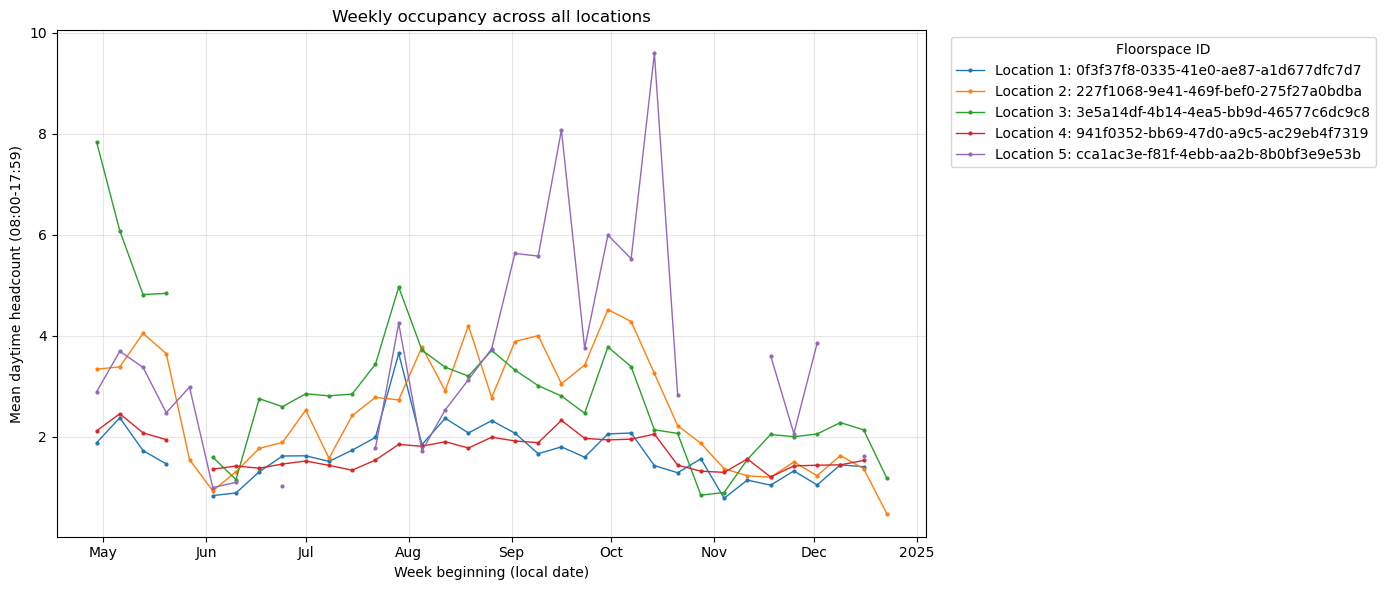

Plot saved to C:\Users\joube\OneDrive - Monash University\Year 5 - Semester 2\MMA3001\MMA3001-Project\derived\occupancy_investigation\reports\occupancy_all_locations_weekly.png.


In [5]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 6))
for location_number, (floorspace_id, group) in enumerate(
    weekly_evidence.groupby("floorspaceid", sort=True), start=1
):
    group = group.sort_values("week_start")
    weekly_headcount = group["weekly_mean_headcount"].where(
        group["eligible_for_week_comparison"]
    )
    dates = pd.to_datetime(group["week_start"])
    ax.plot(
        dates,
        weekly_headcount,
        marker=".",
        markersize=4,
        linewidth=1,
        label=f"Location {location_number}: {floorspace_id}",
    )

# Mark the start of official break and assessment periods from the documented calendar.
event_colors = {
    "mid-semester break": "#9467bd",
    "SWOTVAC": "#d62728",
    "final assessments": "#ff7f0e",
    "inter-semester break": "#2ca02c",
}
plot_start = pd.to_datetime(weekly_evidence["week_start"]).min()
plot_end = pd.to_datetime(weekly_evidence["week_start"]).max()
event_markers = []
for event_start, _, phase in CALENDAR:
    event_kind = next((kind for kind in event_colors if kind in phase), None)
    if event_kind is not None:
        event_markers.append((pd.Timestamp(event_start), phase, event_colors[event_kind]))

semester_1_exam_end = max(
    pd.Timestamp(end)
    for _, end, phase in CALENDAR
    if phase == "Semester 1 final assessments"
)
semester_2_start = min(
    pd.Timestamp(start)
    for start, _, phase in CALENDAR
    if phase == "Semester 2 teaching weeks 1-3"
)
next_week_start = semester_1_exam_end + pd.Timedelta(days=1)
inter_semester_start = next_week_start + pd.Timedelta(
    days=(7 - next_week_start.weekday()) % 7
)
if inter_semester_start < semester_2_start:
    event_markers.append(
        (inter_semester_start, "Inter-semester break", event_colors["inter-semester break"])
    )

for event_date, phase, color in event_markers:
    if plot_start <= event_date <= plot_end:
        short_phase = phase.replace("Semester 1", "S1").replace("Semester 2", "S2")
        ax.axvline(event_date, color=color, linestyle="--", linewidth=1.2, alpha=0.85)
        ax.text(
            event_date,
            1.01,
            short_phase,
            transform=ax.get_xaxis_transform(),
            rotation=90,
            ha="left",
            va="bottom",
            fontsize=8,
            color=color,
            clip_on=False,
        )

ax.set_title("Weekly occupancy across all locations")
ax.set_xlabel("Week beginning (local date)")
ax.set_ylabel("Mean daytime headcount (08:00-17:59)")
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.grid(True, alpha=0.3)
ax.legend(title="Floorspace ID", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout(rect=(0, 0, 0.84, 0.84))

plot_path = OUTPUT_DIR / "occupancy_all_locations_weekly.png"
fig.savefig(plot_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Plot saved to {plot_path}.")

## Hourly occupancy by day of the week

The following seven figures each compare all five locations by local hour for one weekday. Values are averages of the observed daily hourly means in the shared analysis window, so days with more sensor events do not receive extra weight. Missing hours remain blank rather than being treated as zero; compare the curves with the underlying coverage in `hourly_evidence`.

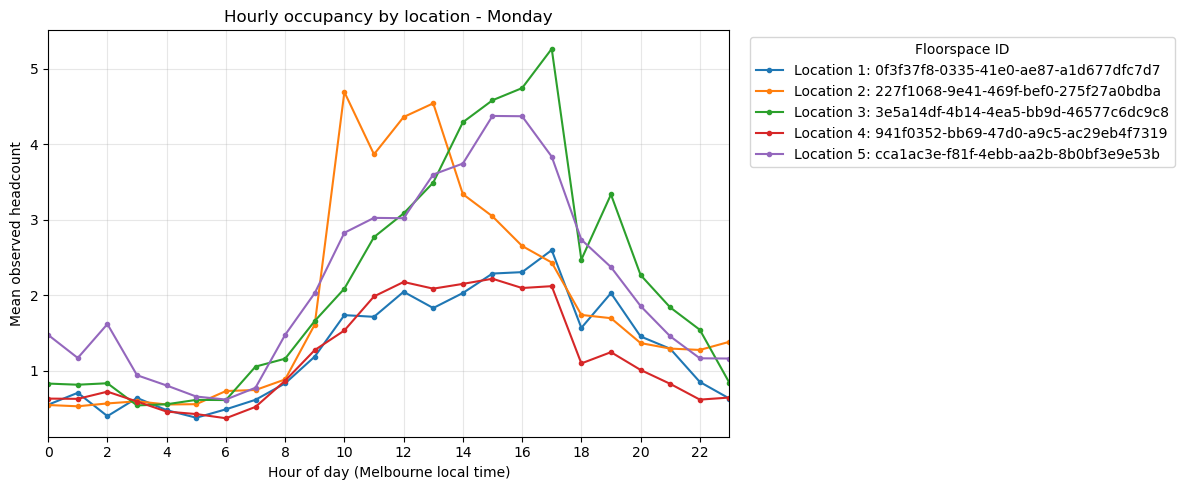

Monday plot saved to C:\Users\joube\OneDrive - Monash University\Year 5 - Semester 2\MMA3001\MMA3001-Project\derived\occupancy_investigation\reports\occupancy_monday_hourly_by_location.png.


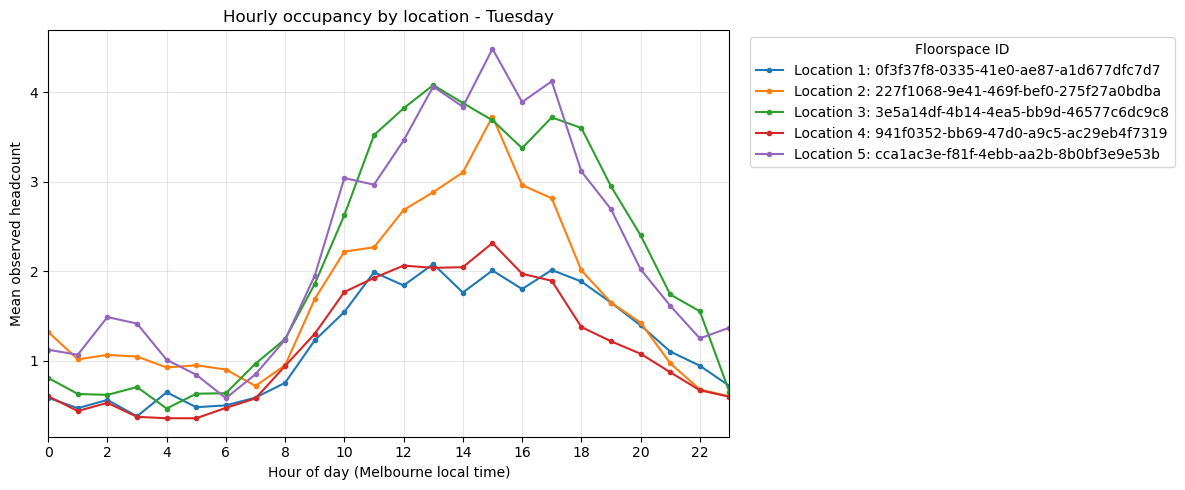

Tuesday plot saved to C:\Users\joube\OneDrive - Monash University\Year 5 - Semester 2\MMA3001\MMA3001-Project\derived\occupancy_investigation\reports\occupancy_tuesday_hourly_by_location.png.


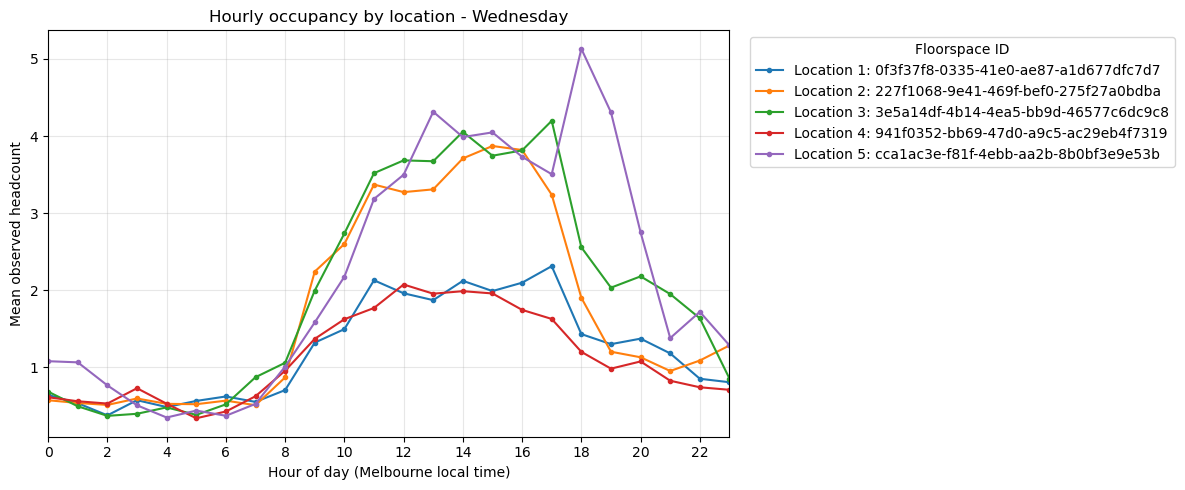

Wednesday plot saved to C:\Users\joube\OneDrive - Monash University\Year 5 - Semester 2\MMA3001\MMA3001-Project\derived\occupancy_investigation\reports\occupancy_wednesday_hourly_by_location.png.


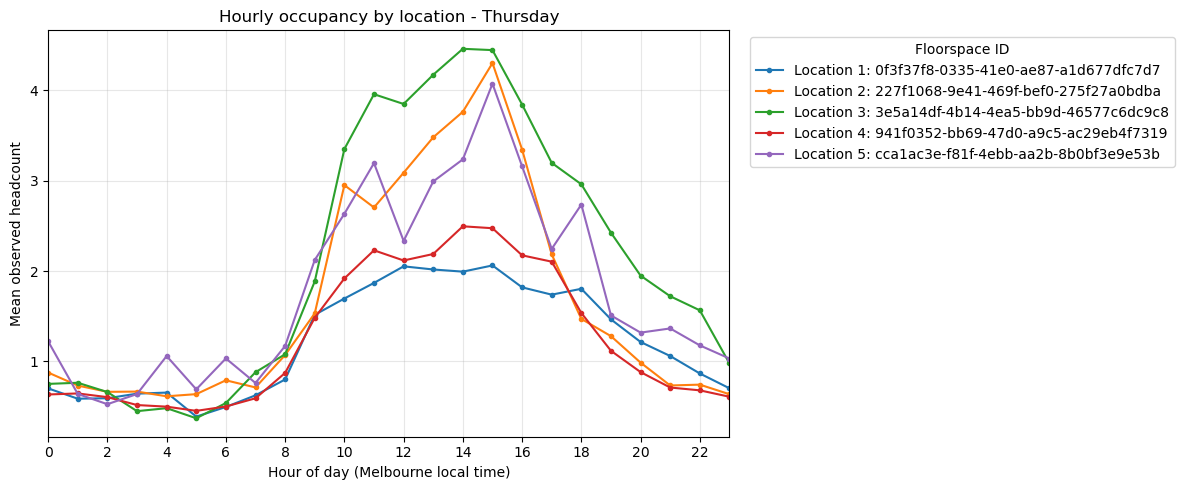

Thursday plot saved to C:\Users\joube\OneDrive - Monash University\Year 5 - Semester 2\MMA3001\MMA3001-Project\derived\occupancy_investigation\reports\occupancy_thursday_hourly_by_location.png.


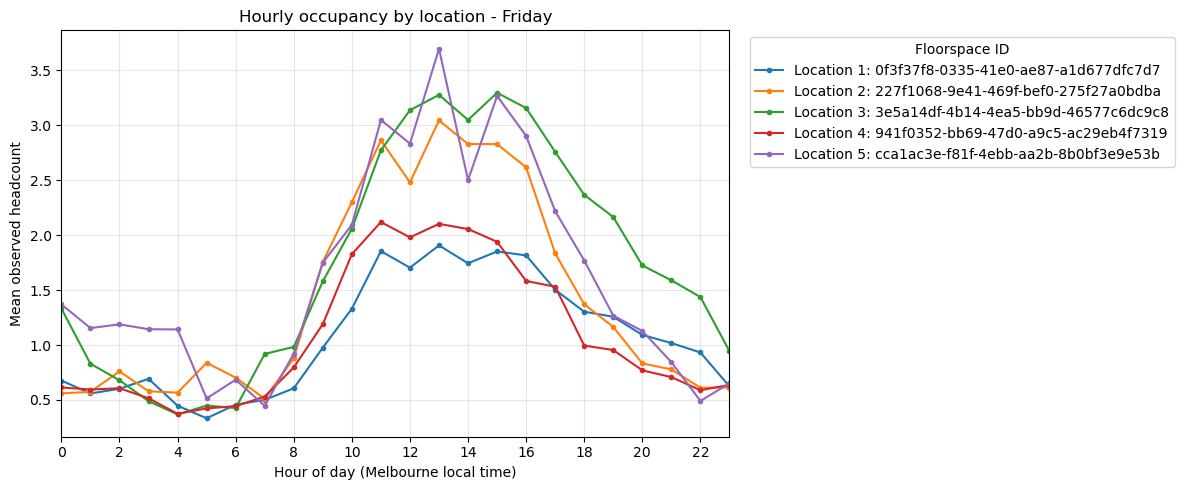

Friday plot saved to C:\Users\joube\OneDrive - Monash University\Year 5 - Semester 2\MMA3001\MMA3001-Project\derived\occupancy_investigation\reports\occupancy_friday_hourly_by_location.png.


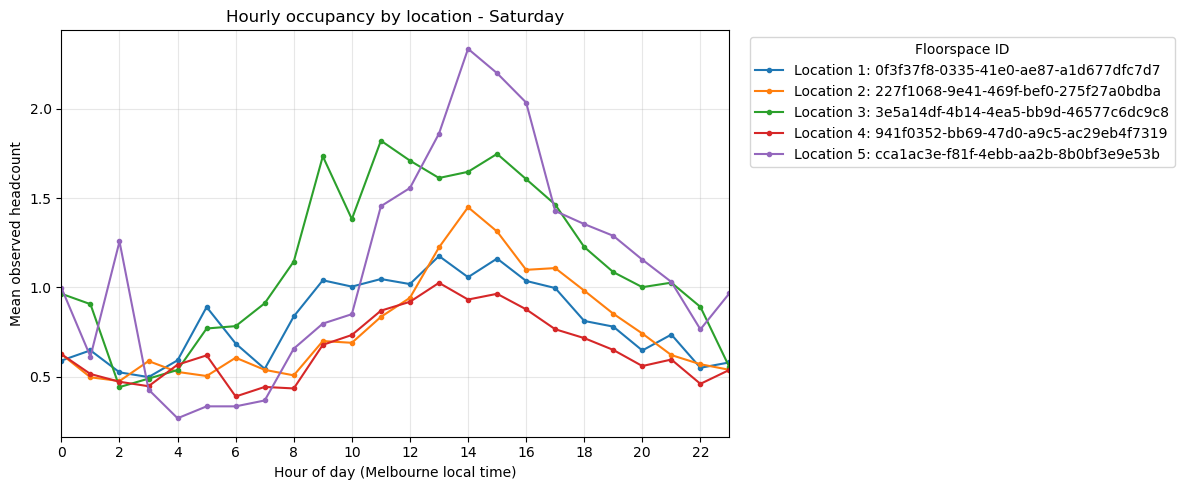

Saturday plot saved to C:\Users\joube\OneDrive - Monash University\Year 5 - Semester 2\MMA3001\MMA3001-Project\derived\occupancy_investigation\reports\occupancy_saturday_hourly_by_location.png.


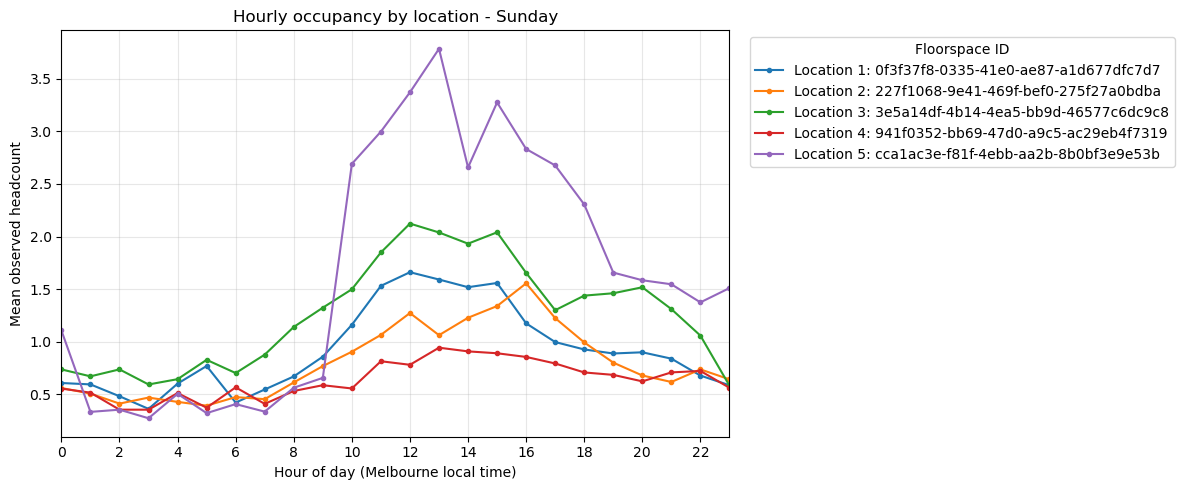

Sunday plot saved to C:\Users\joube\OneDrive - Monash University\Year 5 - Semester 2\MMA3001\MMA3001-Project\derived\occupancy_investigation\reports\occupancy_sunday_hourly_by_location.png.


In [6]:
weekday_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
hourly_location_ids = sorted(hourly_evidence["floorspaceid"].unique())
hourly_by_weekday = (hourly_evidence
    .groupby(["floorspaceid", "weekday", "local_hour"], as_index=False)
    .agg(mean_headcount=("mean_headcount", "mean"),
         observed_days=("local_date", "nunique")))

for weekday, weekday_name in enumerate(weekday_names):
    weekday_data = hourly_by_weekday[hourly_by_weekday["weekday"].eq(weekday)]
    fig, ax = plt.subplots(figsize=(12, 5))
    for location_number, floorspace_id in enumerate(hourly_location_ids, start=1):
        location_data = weekday_data[weekday_data["floorspaceid"].eq(floorspace_id)]
        hourly_profile = (location_data.set_index("local_hour")["mean_headcount"]
                          .reindex(range(24)))
        ax.plot(
            range(24),
            hourly_profile,
            marker="o",
            markersize=3,
            linewidth=1.5,
            label=f"Location {location_number}: {floorspace_id}",
        )

    ax.set_title(f"Hourly occupancy by location - {weekday_name}")
    ax.set_xlabel("Hour of day (Melbourne local time)")
    ax.set_ylabel("Mean observed headcount")
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlim(0, 23)
    ax.grid(True, alpha=0.3)
    ax.legend(title="Floorspace ID", bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()

    plot_path = OUTPUT_DIR / f"occupancy_{weekday_name.lower()}_hourly_by_location.png"
    fig.savefig(plot_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"{weekday_name} plot saved to {plot_path}.")

## 4. Final evidence and conclusion (complete after analysis)

For each hypothesis, enter the estimate, uncertainty, coverage, and whether evidence supports, fails to support, or is inconclusive. Distinguish **association**, **prediction**, and **causation**. If a forecast is included, report the chronological test dates and baseline/model metrics side by side. Tie any operational recommendation to the measured effect and state what evidence would be needed before acting.

### Results to report

- Actual sensor data start/end, floorspace coverage, timestamp timezone, cadence findings, missingness, and any exclusions.
- Calendar source and date boundaries; H1 phase contrasts and baseline-versus-phase model validation.
- Weekly occupancy measure, material-drop rule, flagged weeks, and persistence-versus-model validation (or why predictive validation was not feasible).
- H3 noon-window definition, daily peak-time distribution, coverage, and sensitivity results.
- Computational choices, credible alternatives, reproducibility details, engineering interpretation, and limitations.

### Limitations to revisit

Observed headcount may not represent unique people or total facility occupancy. Space purpose/capacity and sensor measurement properties may be unknown. One year's partial record may not capture recurring semester behavior. Calendar phases can coincide with holidays, weather, operating hours, and other unmeasured factors. Temporal autocorrelation reduces effective sample size. These results alone cannot demonstrate that semester events cause occupancy changes.